2/6: Loading CoreML model and detecting trees on ExG-segmented image...
Detected 47 valid trees; filtered out 0 undersized and 0 oversized detections.
3/6: Calculating VARI map and tree-level statistics...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x

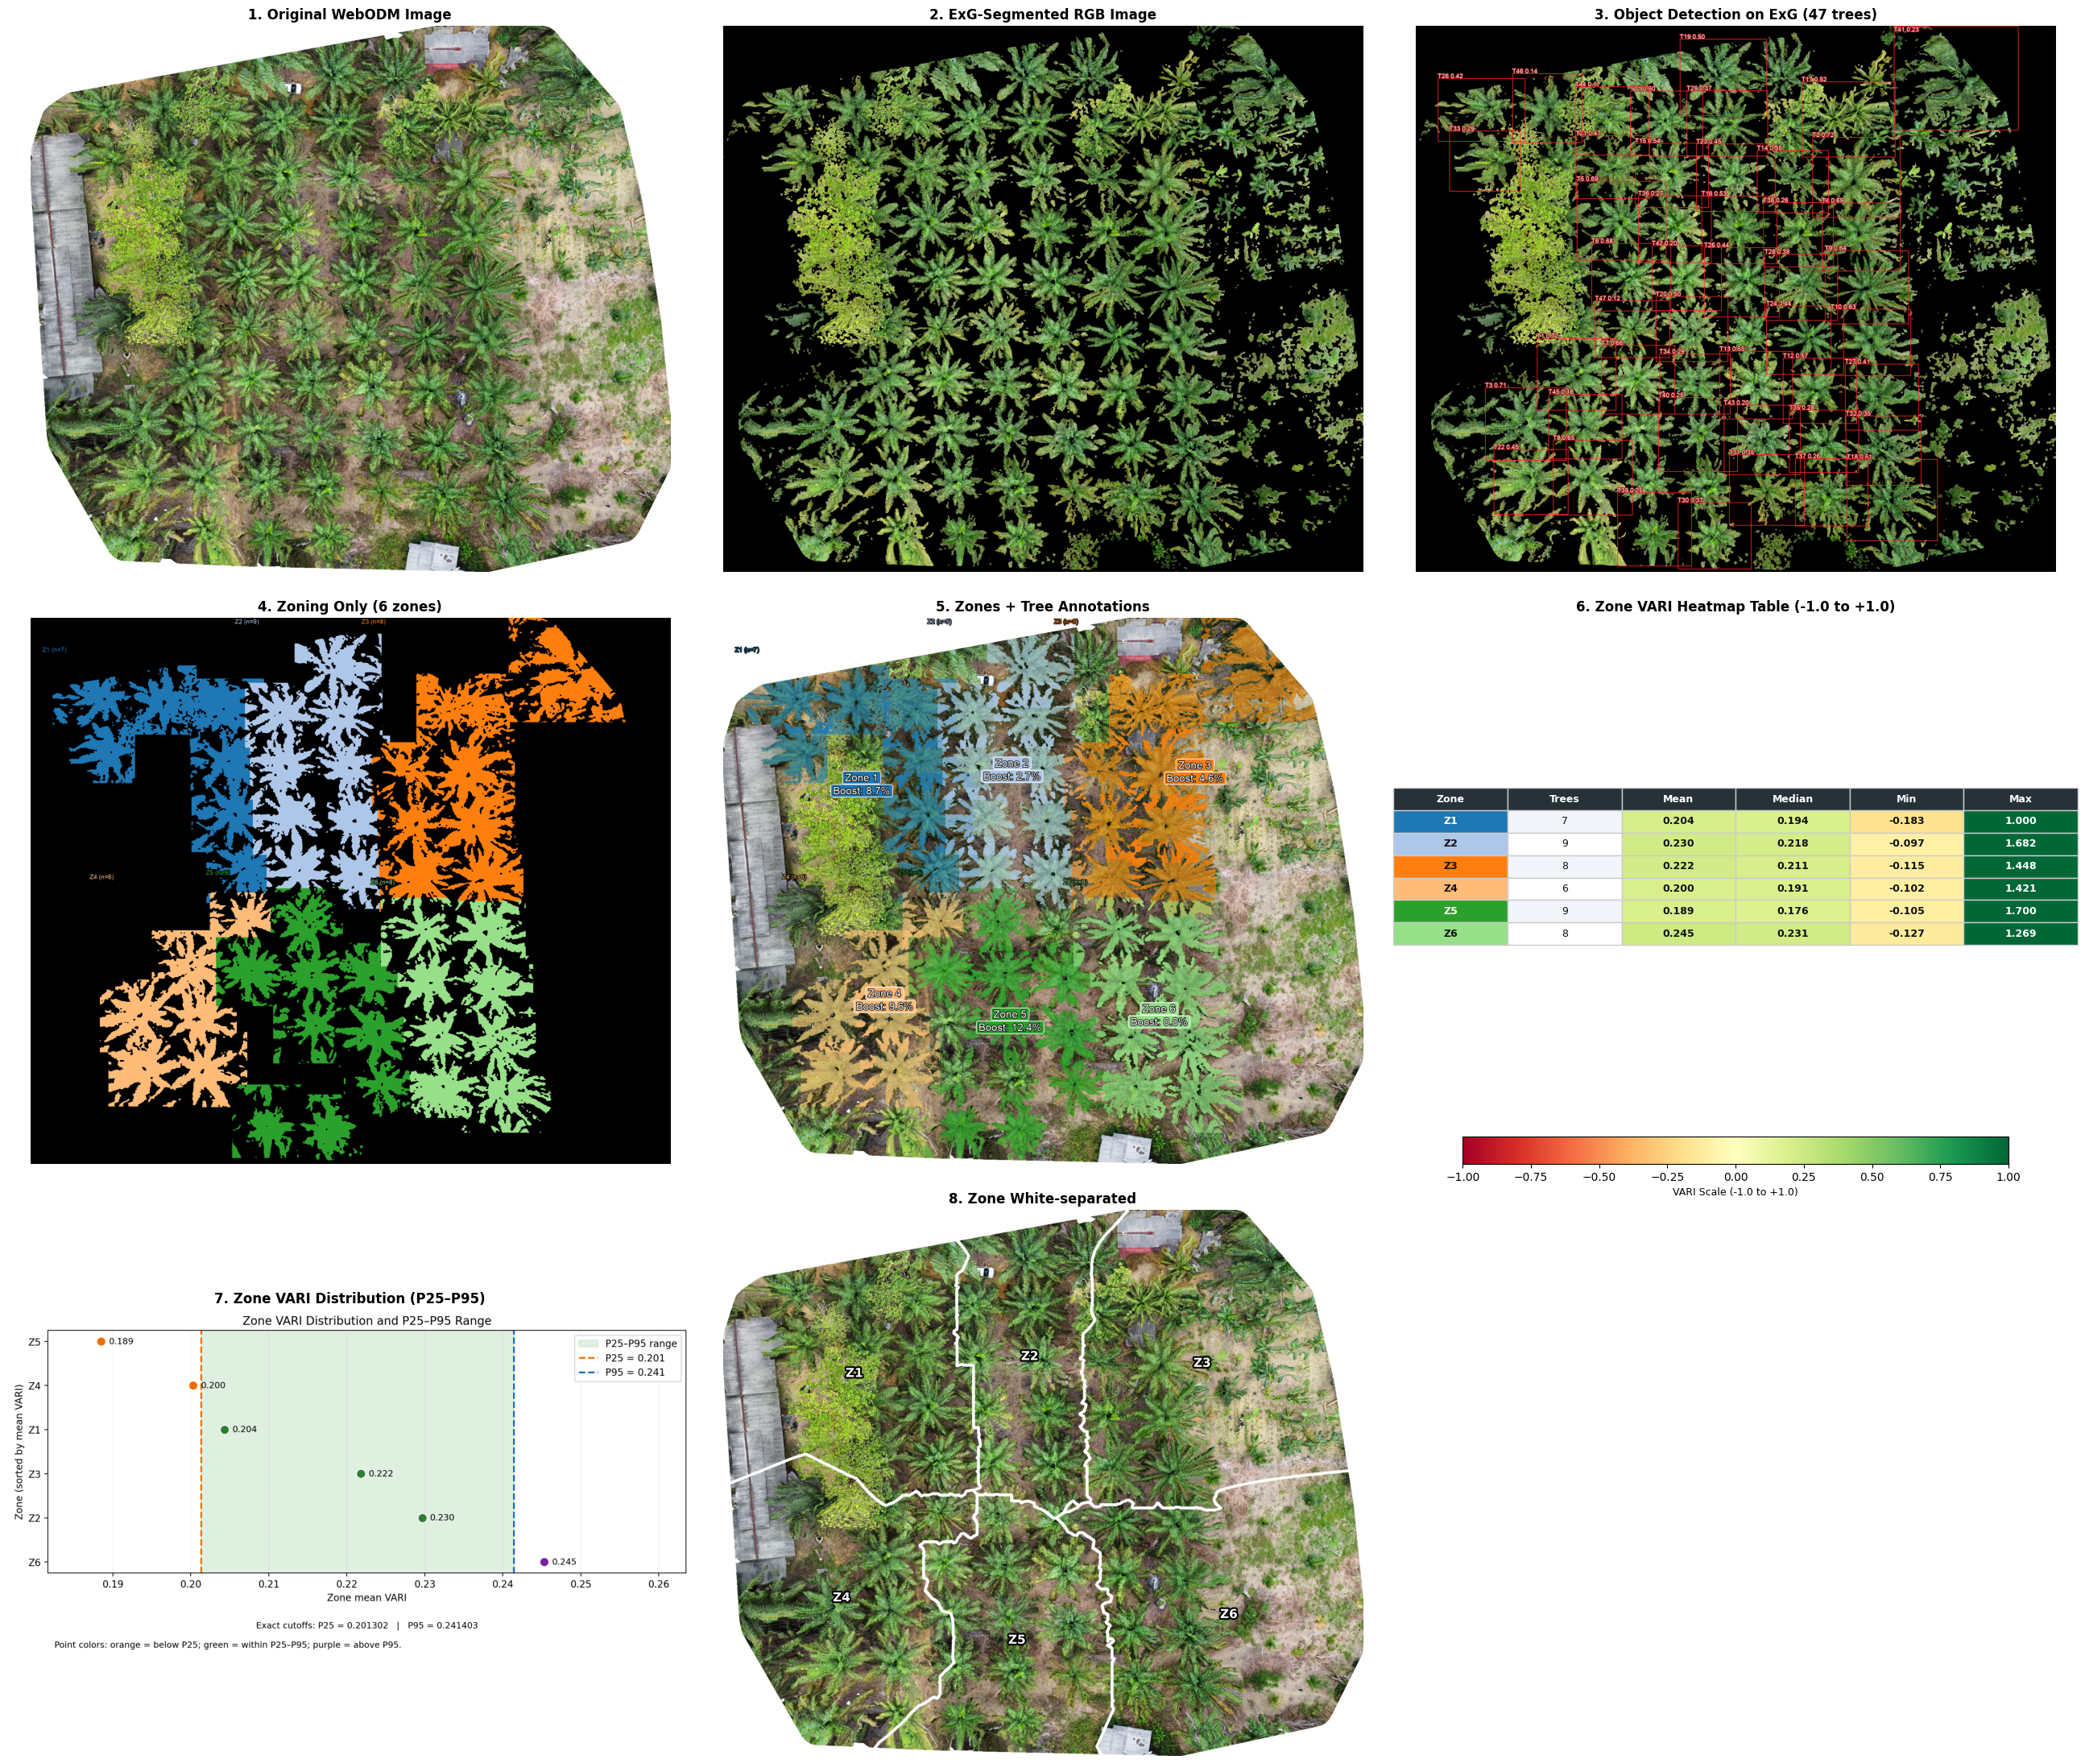

In [2]:
"""Oil-palm zoning + VARI analysis for a WebODM RGB image.
Pipeline:
1. ExG vegetation segmentation
2. CoreML object detection on the ExG-segmented image
3. Spatial grouping of detections into zones containing up to N trees
4. Annotated images for each stage (ExG RGB, CoreML on ExG, and Zones on Original)
5. VARI statistics per tree and per zone, using ExG vegetation pixels
6. JSON and CSV export with pixel and normalized coordinates
Run on macOS with coremltools and the required model installed.
"""
import csv
import json
from pathlib import Path
import coremltools as ct
import cv2
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
import numpy as np
from PIL import Image, ImageDraw, ImageFont
 # ------------------------- Configuration -------------------------
IMAGE_PATH = "webodm_new_2nd_flight.jpeg"  # Input RGB image to segment, detect palms, calculate VARI, and zone.
# IMAGE_PATH = "webodm_last_image_1st_flight.jpeg"
MODEL_PATH = "krops_model_v0.2_yolo26l.mlpackage"  # CoreML object-detection model used to detect palm trees.
# MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"  # CoreML object-detection model used to detect palm trees.
OUTPUT_JSON = "oil_palm_zones_vari.json"  # JSON with metadata, zone/tree statistics, and recommendations.
OUTPUT_ZONE_CSV = "oil_palm_zone_vari_summary.csv"  # CSV with one row per zone and its VARI/fertilizer values.
OUTPUT_PRODUCT_MASS_CSV = "oil_palm_zone_fertilizer_product_mass.csv"  # CSV converting elemental nutrient totals to product mass.
OUTPUT_EXG_MASK = "oil_palm_exg_mask.png"  # Binary vegetation mask produced by ExG thresholding.
OUTPUT_EXG_SEGMENTED = "oil_palm_exg_segmented.jpg"  # RGB image showing pixels retained by the ExG vegetation mask.
OUTPUT_COREML_ANNOTATED = "oil_palm_coreml_detections.jpg"  # ExG-segmented image with detected palm boxes and labels.
OUTPUT_ZONE_ANNOTATED = "oil_palm_zones_only.jpg"  # Black background with detected tree pixels colored by zone.
OUTPUT_ANNOTATED_IMAGE = "oil_palm_zones_annotated.jpg"  # Original image with zone colors, tree labels, and boost overlays.
OUTPUT_WHITE_ZONE_ANNOTATED = "oil_palm_zones_white_separators.jpg"  # Original image with white zone boundaries and no zone-color fill.
WHITE_ZONE_BOUNDARY_WIDTH_PX = 9  # Thickness of the white-only shared zone boundaries in the separator image.
OUTPUT_ZONE_BASE_CROPS_DIR = "oil_palm_zone_base_crops"  # Folder for original-image crops, one per zone.
OUTPUT_ZONE_EXG_CROPS_DIR = "oil_palm_zone_exg_crops"  # Folder for ExG-segmented image crops, one per zone.
OUTPUT_PIPELINE_PLOT = "oil_palm_pipeline_stages.jpg"  # Combined visualization of the analysis pipeline outputs.
OUTPUT_VARI_DISTRIBUTION = "oil_palm_vari_distribution.png"  # Zone mean VARI values with the P25–P95 range highlighted.
CONF_THRESHOLD = 0.10  # Temporary recall-focused cutoff; inspect lower-confidence detections for false positives.
IOU_THRESHOLD = 0.45  # Non-maximum suppression overlap threshold for removing duplicate detections.
MODEL_INPUT_SIZE = 640  # Width and height, in pixels, of the square image passed to the CoreML model.
ZONE_GRID_ROWS = 3  # Target number of palm rows grouped into one zone band.
ZONE_GRID_COLS = 3  # Target number of palms per row within a zone; nominal capacity is rows × columns.
TREES_PER_ZONE = ZONE_GRID_ROWS * ZONE_GRID_COLS  # Nominal tree capacity used to mark zones as undersized.
MIN_TREES_TO_KEEP_ZONE = 2  # Merge a one-tree spatial zone into a directly adjacent zone when possible.
ROW_TOLERANCE_MULTIPLIER = 0.75  # Same-row center tolerance as a fraction of median detected tree height.
MAX_ZONE_DISTANCE_MULTIPLIER = 3.0  # Maximum row/column grouping gap as a fraction of median tree height.
ZONE_PADDING_MULTIPLIER = 0.15  # Padding around each zone bounding box as a fraction of median tree height.
MIN_TREE_COMPLETENESS = 0.70  # Keep a detection only if its width, height, and area are each >=70% of their medians.
MAX_TREE_DIMENSION_MULTIPLIER = 4.0  # Reject extreme boxes wider or taller than 4× the robust typical tree box.
MAX_TREE_AREA_MULTIPLIER = 20.0  # Reject extreme boxes with area greater than 20× the robust typical tree-box area.
BORDER_MARGIN_PX = 5  # Exclude detections whose bounding boxes come within 5 pixels of any image edge.
SHOW_PLOTS = True  # Display the generated pipeline figure interactively after saving it.
# If the spread between zone-mean VARI P95 and P25 is at or below this
# configured absolute VARI gap, use the P25-derived boost across all zones.
# Tune this threshold for the imagery and management policy; set to 0.0 to
# effectively disable the blanket mode for a nonzero spread.
MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST = 0.03
# Maximum annual elemental Mg and N nutrient rates per hectare/year, supplied
# by the user. These are nutrient quantities, independent of product choice.
# Zone targets are B_i × the corresponding nutrient rate.
MAX_NUTRIENT_KG_HA_PER_YEAR = {
    "Mg": 13.0,
    "N": 90.0,
}
FERTILIZER_NUTRIENT_BY_PRODUCT = {
    "kieserite_Mg_expensive": "Mg", "dolomite_Mg_cheaper": "Mg",
    "ZA_N_cheaper": "N", "urea_N_expensive": "N",
}
# Product label fractions in the form printed on the bag. Mg fertilizers use
# MgO labels; N fertilizers use elemental N labels. Set each product guarantee
# here once. Product kg is calculated in two steps: nutrient -> label basis -> product.
FERTILIZER_PRODUCT_LABEL_FRACTIONS = {
    "kieserite_Mg_expensive": {"basis": "MgO", "fraction": 0.255},
    "dolomite_Mg_cheaper": {"basis": "MgO", "fraction": 0.22},
    "ZA_N_cheaper": {"basis": "N", "fraction": 0.21},
    "urea_N_expensive": {"basis": "N", "fraction": 0.46},
}
MGO_TO_MG_FACTOR = 24.305 / 40.304  # Elemental Mg mass contained in one unit of MgO mass.
MG_TO_MGO_FACTOR = 40.304 / 24.305  # MgO mass equivalent to one unit of elemental Mg mass.
# Derived elemental nutrient per kg product fractions. These are calculated
# from the single label configuration above and should not be edited separately.
FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS = {
    product: config["fraction"] * (MGO_TO_MG_FACTOR if config["basis"] == "MgO" else 1.0)
    for product, config in FERTILIZER_PRODUCT_LABEL_FRACTIONS.items()
}
# Optional full annual product rates, separate from VARI-derived supplements.
# Enter approved rates in kg product/palm/year. None means no base amount is
# included for that product; configured base and boost amounts remain separate.
KIESERITE_BASE_PRODUCT_KG_PER_PALM_PER_YEAR = None
DOLOMITE_BASE_PRODUCT_KG_PER_PALM_PER_YEAR = None
ZA_BASE_PRODUCT_KG_PER_PALM_PER_YEAR = None
UREA_BASE_PRODUCT_KG_PER_PALM_PER_YEAR = None
FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR = {
    "kieserite_Mg_expensive": KIESERITE_BASE_PRODUCT_KG_PER_PALM_PER_YEAR,
    "dolomite_Mg_cheaper": DOLOMITE_BASE_PRODUCT_KG_PER_PALM_PER_YEAR,
    "ZA_N_cheaper": ZA_BASE_PRODUCT_KG_PER_PALM_PER_YEAR,
    "urea_N_expensive": UREA_BASE_PRODUCT_KG_PER_PALM_PER_YEAR,
}
# Optional costs are in a user-selected currency per kg of fertilizer product.
# Leave empty (or omit a product) to suppress cost outputs.
FERTILIZER_PRICE_PER_KG = {}
# Provide ground area per zone in hectares. Either use a JSON file such as
# {"1": 0.25, "2": 0.30}, or a uniform hectare value for every zone.
# If neither is supplied, TOTAL_FARM_AREA_HA is split across zones by detected
# tree count. Set it to 2.0 to double area-based totals relative to 1.0 ha.
ZONE_AREA_HA_BY_ID = {}
ZONE_AREA_JSON_PATH = None
UNIFORM_ZONE_AREA_HA = None  # Optional override applied to every zone
TOTAL_FARM_AREA_HA = 1.0  # Total field area; default nutrient-rate basis is 1 ha.
# Default approximation from palm spacing. Midpoint of the supplied 9–11 m
# gap is 10 m, or 0.01 ha per palm. Zone area scales with detected tree count.
DEFAULT_TREE_SPACING_M = 10.0
USE_SPACING_BASED_ZONE_AREA_DEFAULT = True
# Optional manual final-confidence overrides by zone ID; leave empty to use the
# confidence calculation below. Each configured value must be in [0.10, 1.0].
ZONE_CONFIDENCE_BY_ID = {}
# Flight-level confidence (L6), when assessed. Until it is assessed, the
# default below stands in as the flight factor and the run/each zone is flagged.
FLIGHT_CONFIDENCE = None
DEFAULT_ZONE_CONFIDENCE = 0.60
# Notebook confidence model (team proposal, values marked GUESS until calibrated).
ZONE_CONFIDENCE_FULL_TREES = 9  # Tree factor reaches 1.0 at this many palms.
ZONE_LEAF_PIXEL_FULL_RATIO = 0.70  # Leaf factor reaches 1.0 at this zone/photo leaf-pixel ratio.
ZONE_REFERENCE_MIN_FACTOR = 0.70  # Zones below this zone factor do not set P25/P95.
ZONE_CONFIDENCE_FLOOR = 0.10  # Keep nonzero boost confidence at or above this floor.
MIN_REFERENCE_ZONES_SUGGESTED = 5  # Emit a metadata note when fewer valid reference zones qualify.
 # -----------------------------------------------------------------
def iou(box1, box2):
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0


def nms(boxes, scores, iou_threshold=0.45):
    if not boxes:
        return []
    order = np.argsort(scores)[::-1]
    selected = []
    while len(order) > 0:
        current = int(order[0])
        selected.append(current)
        order = np.asarray([
            int(j) for j in order[1:]
            if iou(boxes[current], boxes[int(j)]) <= iou_threshold
        ], dtype=int)
    return selected


def segment_vegetation_exg(image_bgr):
    """Create an ExG/Otsu mask. This is a heuristic vegetation mask, not a crown model."""
    b, g, r = cv2.split(image_bgr)
    exg = 2.0 * g.astype(np.float32) - r.astype(np.float32) - b.astype(np.float32)
    exg_u8 = cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, mask = cv2.threshold(exg_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    segmented = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)
    return mask, segmented


def parse_coreml_predictions(model, rgb_image):
    """Parse the [1, 5, N] / [1, N, 5] single-class output assumed by the source script.
    Expected prediction rows: [cx, cy, width, height, confidence] in 640x640 pixels.
    """
    input_names = list(model.input_description)
    if not input_names:
        raise RuntimeError("The CoreML model has no declared input.")
    pil_image = Image.fromarray(rgb_image).convert("RGB").resize(
        (MODEL_INPUT_SIZE, MODEL_INPUT_SIZE)
    )
    prediction = model.predict({input_names[0]: pil_image})
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])
    raw = np.squeeze(raw)
    if raw.ndim != 2:
        raise ValueError(f"Unexpected model output shape {raw.shape}; expected a 2D array after squeeze.")
    if raw.shape[0] == 5:
        rows = raw.T
    elif raw.shape[1] == 5:
        rows = raw
    else:
        raise ValueError(
            f"Model output shape {raw.shape} does not have a 5-value detection axis. "
            "Inspect the CoreML output schema and update parse_coreml_predictions()."
        )
    boxes, scores = [], []
    for row in rows:
        cx, cy, width, height, confidence = map(float, row[:5])
        if not np.isfinite([cx, cy, width, height, confidence]).all() or confidence < CONF_THRESHOLD:
            continue
        box = [
            np.clip((cx - width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy - height / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cx + width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy + height / 2) / MODEL_INPUT_SIZE, 0, 1),
        ]
        if box[2] > box[0] and box[3] > box[1]:
            boxes.append([float(v) for v in box])
            scores.append(confidence)
    keep = nms(boxes, scores, IOU_THRESHOLD)
    return [boxes[i] for i in keep], [scores[i] for i in keep]


def normalized_box_to_pixels(box, width, height):
    x1, y1, x2, y2 = box
    return [
        max(0, min(width, int(round(x1 * width)))),
        max(0, min(height, int(round(y1 * height)))),
        max(0, min(width, int(round(x2 * width)))),
        max(0, min(height, int(round(y2 * height)))),
    ]


def stats_for_box(vari_map, exg_mask, bbox):
    x1, y1, x2, y2 = bbox
    if x2 <= x1 or y2 <= y1:
        values = np.asarray([], dtype=np.float32)
    else:
        vari_crop = vari_map[y1:y2, x1:x2]
        mask_crop = exg_mask[y1:y2, x1:x2] > 0
        values = vari_crop[mask_crop & np.isfinite(vari_crop)]
    if values.size == 0:
        return {
            "vegetation_pixel_count": 0,
            "mean_vari": None,
            "median_vari": None,
            "std_vari": None,
            "mad_vari": None,
            "min_vari": None,
            "max_vari": None,
        }
    median = float(np.median(values))
    return {
        "vegetation_pixel_count": int(values.size),
        "mean_vari": float(np.mean(values)),
        "median_vari": median,
        "std_vari": float(np.std(values)),
        "mad_vari": float(np.median(np.abs(values - median))),
        "min_vari": float(np.min(values)),
        "max_vari": float(np.max(values)),
    }


def group_trees_into_zones(
    trees,
    grid_rows=3,
    grid_cols=3,
    row_tolerance_multiplier=0.75,
    max_zone_distance_multiplier=3.0,
    zone_padding_multiplier=0.15,
    image_width=None,
    image_height=None,
    ):
    """Group detected palms by approximate row bands and fixed spatial column blocks."""
    if grid_rows < 1 or grid_cols < 1:
        raise ValueError("grid_rows and grid_cols must be at least 1.")
    if not trees:
        return []
    target_trees_per_zone = grid_rows * grid_cols
 # 1. Estimate typical tree size
    heights = [max(1, tree["bbox"][3] - tree["bbox"][1]) for tree in trees]
    median_height = float(np.median(heights))
    row_tolerance = max(1.0, median_height * row_tolerance_multiplier)
    max_zone_distance = max(1.0, median_height * max_zone_distance_multiplier)
    padding = max(0, int(median_height * zone_padding_multiplier))
 # 2. Cluster trees into approximate horizontal rows
    ordered = sorted(trees, key=lambda tree: (tree["center"][1], tree["center"][0]))
    rows = []
    for tree in ordered:
        cy = tree["center"][1]
        best_row = None
        best_distance = float("inf")
        for row in rows:
            row_center = float(np.median([item["center"][1] for item in row]))
            distance = abs(cy - row_center)
            if distance <= row_tolerance and distance < best_distance:
                best_row = row
                best_distance = distance
        if best_row is None:
            rows.append([tree])
        else:
            best_row.append(tree)
    rows.sort(key=lambda row: float(np.median([tree["center"][1] for tree in row])))
    for row in rows:
        row.sort(key=lambda tree: tree["center"][0])
 # 3. Group consecutive rows into bands of up to `grid_rows` (3 rows)
    row_bands = []
    current_band = []
    for row in rows:
        if not current_band:
            current_band.append(row)
        else:
            prev_row_y = float(np.median([t["center"][1] for t in current_band[-1]]))
            curr_row_y = float(np.median([t["center"][1] for t in row]))
            if len(current_band) >= grid_rows or (curr_row_y - prev_row_y) > max_zone_distance:
                row_bands.append(current_band)
                current_band = [row]
            else:
                current_band.append(row)
    if current_band:
        row_bands.append(current_band)
 # 4. Within each row band, assign trees to fixed spatial column blocks.
 # Missing detections leave empty positions instead of shifting later trees.
    zones = []
    row_gaps = []
    for row in rows:
        row_x = sorted(float(tree["center"][0]) for tree in row)
        row_gaps.extend(
            gap for gap in np.diff(row_x)
            if gap > 0 and gap <= max_zone_distance
        )
    typical_column_spacing = float(np.median(row_gaps)) if row_gaps else max(1.0, median_height * 2.0)
    global_x_origin = min(float(tree["center"][0]) for tree in trees)
    spatial_block_width = max(1.0, typical_column_spacing * grid_cols)
    for band_idx, band in enumerate(row_bands, start=1):
        band_trees = [tree for row in band for tree in row]
 # Assign by fixed x intervals, not by chunks or gaps in detected-tree counts.
        spatial_blocks = {}
        for tree in band_trees:
            block_id = int(np.floor((tree["center"][0] - global_x_origin) / spatial_block_width))
            spatial_blocks.setdefault(block_id, []).append(tree)
        for block_id in sorted(spatial_blocks):
            members = spatial_blocks[block_id]
            x1 = min(t["bbox"][0] for t in members) - padding
            y1 = min(t["bbox"][1] for t in members) - padding
            x2 = max(t["bbox"][2] for t in members) + padding
            y2 = max(t["bbox"][3] for t in members) + padding
            if image_width is not None:
                x1 = max(0, x1)
                x2 = min(image_width, x2)
            if image_height is not None:
                y1 = max(0, y1)
                y2 = min(image_height, y2)
            zones.append({
                "zone_id": len(zones) + 1,
                "approx_row": band_idx,
                "spatial_column_block": block_id,
                "trees": members,
                "bbox": [x1, y1, x2, y2],
                "is_undersized": len(members) < target_trees_per_zone,
            })
    return zones


def merge_small_adjacent_zones(zones, min_tree_count=MIN_TREES_TO_KEEP_ZONE):
    """Merge undersized zones into the nearest zone in an adjacent grid cell."""
    zones = list(zones)
    for source in sorted(zones, key=lambda item: (len(item["trees"]), item["zone_id"])):
        if source not in zones or len(source["trees"]) >= min_tree_count:
            continue
        source_row = source.get("approx_row")
        source_col = source.get("spatial_column_block")
        source_center = np.mean([tree["center"] for tree in source["trees"]], axis=0)
        candidates = []
        for target in zones:
            if target is source:
                continue
            row_delta = abs(target.get("approx_row", source_row) - source_row)
            col_delta = abs(target.get("spatial_column_block", source_col) - source_col)
            if row_delta <= 1 and col_delta <= 1:
                target_center = np.mean([tree["center"] for tree in target["trees"]], axis=0)
                distance = float(np.linalg.norm(source_center - target_center))
                candidates.append((distance, target))
        if not candidates:
            continue
        _, target = min(candidates, key=lambda item: item[0])
        target["trees"].extend(source["trees"])
        target["bbox"] = [
            min(target["bbox"][0], source["bbox"][0]),
            min(target["bbox"][1], source["bbox"][1]),
            max(target["bbox"][2], source["bbox"][2]),
            max(target["bbox"][3], source["bbox"][3]),
        ]
        target.setdefault("merged_from_zone_ids", []).extend(
            source.get("merged_from_zone_ids", [source["zone_id"]])
        )
        zones.remove(source)
    zones.sort(key=lambda item: (item.get("approx_row", 0), item.get("spatial_column_block", 0)))
    for new_zone_id, zone in enumerate(zones, start=1):
        zone["zone_id"] = new_zone_id
        zone["is_undersized"] = len(zone["trees"]) < TREES_PER_ZONE
    return zones


def pixel_bbox_record(bbox, image_width, image_height):
    x1, y1, x2, y2 = map(int, bbox)
    return {
        "x1": x1, "y1": y1, "x2": x2, "y2": y2,
        "width": x2 - x1,
        "height": y2 - y1,
        "normalized_xyxy": [
            x1 / image_width, y1 / image_height,
            x2 / image_width, y2 / image_height,
        ],
    }


def print_zone_vari_table(zone_json):
    """Print annual VARI-derived elemental nutrient supplements by zone."""
    nutrients = [nutrient for nutrient, rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items() if rate is not None]
    headers = ["Zone", "Trees", "Mean VARI", "Min VARI", "Min VARI review",
               "Zone factor", "Zone confidence", "Overall field confidence (applied)",
               "Qualifies for P25/P95?", "Raw zone boost", "Boost mode / basis",
               *[f"Additional {nutrient} boost only" for nutrient in nutrients]]
    valid_means = [float(z["vari"]["mean_vari"]) for z in zone_json
                   if z.get("vari", {}).get("mean_vari") is not None
                   and np.isfinite(z["vari"]["mean_vari"])]
    rows = []
    def fmt(value, digits=3):
        if value is None:
            return "N/A"
        if isinstance(value, (int, np.integer)):
            return f"{value:,}"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{digits}f}" if np.isfinite(value) else "N/A"
        return str(value)
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        boost = rec.get("boost_fraction")
        mean = zone.get("vari", {}).get("mean_vari")
        if boost is None:
            boost_mode_text = "Unavailable"
        elif rec.get("boost_mode") == "blanket_p25":
            boost_mode_text = f"Blanket (P25={rec.get('p25_zone_mean_vari'):.3f}): {100 * boost:.1f}%"
        else:
            boost_mode_text = f"Zone-specific: {100 * boost:.1f}%"
        row = [f"Z{zone['zone_id']}", fmt(zone.get("tree_count")),
               fmt(mean),
               fmt(zone.get("vari", {}).get("min_vari")),
               ("CHECK: lowest zone min" if zone.get("vari", {}).get("lowest_min_vari_zone") else "—"),
               fmt(zone.get("confidence", {}).get("zone_factor"), digits=4),
               fmt(zone.get("confidence", {}).get("confidence"), digits=4),
               fmt(rec.get("overall_field_confidence"), digits=4),
               ("yes" if zone.get("confidence", {}).get("reference_zone") else "no"),
               (f"{100 * rec['zone_specific_boost_fraction']:.1f}%" if rec.get("zone_specific_boost_fraction") is not None else "N/A"),
               boost_mode_text]
        for nutrient in nutrients:
            product = next((name for name, mapped_nutrient in FERTILIZER_NUTRIENT_BY_PRODUCT.items()
                            if mapped_nutrient == nutrient and name in rec.get("fertilizers", {})), None)
            item = rec.get("fertilizers", {}).get(product, {}) if product is not None else {}
            total = item.get("annual_total_kg")
            per_palm = item.get("kg_per_palm_per_year")
            row.append(f"{fmt(total, digits=4)} kg/zone/year; "
                       f"{fmt(per_palm, digits=4)} kg/palm/year")
        rows.append(row)
    widths = [max(len(header), *(len(row[i]) for row in rows)) if rows else len(header)
              for i, header in enumerate(headers)]
    print("\n--- Zone VARI-Derived Nutrient Supplement Summary (annual) ---")
    overall_field_confidence = (zone_json[0].get("recommendation", {}).get("overall_field_confidence")
                                if zone_json else None)
    print("Notebook confidence thresholds are proposals/guesses pending calibration against field observations.")
    print("Min VARI review flags every zone tied for the lowest valid zone minimum; it is a screening flag for follow-up, not a diagnosis.")
    print(" | ".join(header.ljust(widths[i]) for i, header in enumerate(headers)))
    print("-+-".join("-" * width for width in widths))
    if not rows:
        print("(No zones were created.)")
    else:
        for row in rows:
            print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))
    print("\nConfidence calculations (section 5b):")
    if zone_json:
        first_confidence = zone_json[0].get("confidence", {})
        median_leaf_px = first_confidence.get("median_leaf_pixels_per_tree", 0.0)
        for zone in zone_json:
            c = zone.get("confidence", {})
            n = max(0, int(zone.get("tree_count", 0)))
            leaf_px = int(c.get("leaf_pixel_count", zone.get("vari", {}).get("vegetation_pixel_count", 0)) or 0)
            tree_factor = float(c.get("tree_factor", 0.0))
            leaf_ratio = float(c.get("leaf_pixel_ratio", 0.0))
            leaf_factor = float(c.get("leaf_pixel_factor", 0.0))
            zone_factor = float(c.get("zone_factor", 0.0))
            local_confidence = float(c.get("confidence", 0.0))
            flight = float(c.get("flight_confidence", 0.0))
            print(f"  Z{zone['zone_id']} (weight = {n} trees):")
            print(f"    Tree factor = min(1, sqrt({n} ÷ {ZONE_CONFIDENCE_FULL_TREES})) = {tree_factor:.4f}")
            if n > 0 and median_leaf_px:
                print(f"    Leaf ratio = {leaf_px} ÷ ({n} × {median_leaf_px:.2f} median leaf pixels/tree) = {leaf_ratio:.4f}")
            else:
                print(f"    Leaf ratio = 0.0000 (no valid tree/leaf-pixel denominator)")
            print(f"    Leaf factor = min(1, {leaf_ratio:.4f} ÷ {ZONE_LEAF_PIXEL_FULL_RATIO:.4f}) = {leaf_factor:.4f}")
            print(f"    Zone factor = {tree_factor:.4f} × {leaf_factor:.4f} = {zone_factor:.4f}")
            if c.get("manual_override") is not None:
                print(f"    Zone confidence = manual override {local_confidence:.4f}")
            else:
                print(f"    Zone confidence = clamp({flight:.4f} flight × {zone_factor:.4f} zone factor, "
                      f"{ZONE_CONFIDENCE_FLOOR:.2f}, 1.00) = {local_confidence:.4f}")
        overall_raw = first_confidence.get("overall_field_confidence_raw")
        total_weight = sum(max(0, int(z.get("tree_count", 0))) for z in zone_json)
        weighted_terms = " + ".join(
            f"({z.get('confidence', {}).get('confidence', 0.0):.4f} × "
            f"{max(0, int(z.get('tree_count', 0)))})" for z in zone_json
        )
        print("  Overall field confidence = tree-count-weighted mean of zone confidences:")
        if overall_raw is not None and total_weight > 0:
            print(f"    ({weighted_terms}) ÷ {total_weight} total trees = {overall_raw:.6f}")
            print(f"    Clamp to [{ZONE_CONFIDENCE_FLOOR:.2f}, 1.00] = {overall_field_confidence:.4f}")
        else:
            print(f"    No detected trees; use confidence floor {ZONE_CONFIDENCE_FLOOR:.2f}")
        print("    This one overall value is used in every zone's boost calculation.")
    print("\nBoost calculation by zone:")
    print("  Vref = 95th percentile of valid zone mean VARI values from reference zones only")
    first_rec = zone_json[0].get("recommendation", {}) if zone_json else {}
    boost_mode = first_rec.get("boost_mode", "zone_specific")
    p25 = first_rec.get("p25_zone_mean_vari")
    p95 = first_rec.get("reference_zone_mean_vari")
    gap = first_rec.get("p95_p25_vari_gap")
    reference_id_set = {str(value) for value in first_rec.get("reference_zone_ids", [])}
    reference_means = [float(z["vari"]["mean_vari"]) for z in zone_json
                       if str(z.get("zone_id")) in reference_id_set
                       and z.get("vari", {}).get("mean_vari") is not None
                       and np.isfinite(z["vari"]["mean_vari"])]
    if first_rec.get("reference_fallback_all_zones"):
        reference_means = valid_means
    sorted_means = sorted(reference_means)
    print("  Reference zone IDs = " + (", ".join(f"Z{zid}" for zid in first_rec.get("reference_zone_ids", [])) or "none"))
    if first_rec.get("reference_fallback_all_zones"):
        print("  No zones qualified, so P25/P95 fall back to all valid zone means.")
    for flag in first_rec.get("zone_confidence_run_flags", []):
        print(f"  Confidence note: {flag}")
    print("  Sorted reference-zone mean VARI values = " + ", ".join(f"{value:.3f}" for value in sorted_means))
    print("  Sorted values use zero-based indexes: " + ", ".join(f"sorted[{i}]={value:.6f}" for i, value in enumerate(sorted_means)))
    if p25 is not None and p95 is not None:
        print(f"  Quantile references (linear interpolation): P25={p25:.3f}; P95={p95:.3f}")
        def print_quantile_steps(label, percentile):
            if not sorted_means:
                return
            position = (len(sorted_means) - 1) * percentile
            lower_index = int(np.floor(position))
            upper_index = int(np.ceil(position))
            fraction = position - lower_index
            lower_value = sorted_means[lower_index]
            upper_value = sorted_means[upper_index]
            result = lower_value + fraction * (upper_value - lower_value)
            if lower_index == upper_index:
                print(f"  {label}: position=({len(sorted_means)}-1)×{percentile:.2f}={position:.2f}; "
                      f"sorted[{lower_index}]={lower_value:.6f}")
            else:
                lower_weight = 1.0 - fraction
                lower_part = lower_weight * lower_value
                upper_part = fraction * upper_value
                print(f"  {label}: position=({len(sorted_means)}-1)×{percentile:.2f}={position:.2f}; "
                      f"interpolate sorted[{lower_index}]={lower_value:.6f} and "
                      f"sorted[{upper_index}]={upper_value:.6f} with fraction {fraction:.2f}: "
                      f"({lower_weight:.2f}×{lower_value:.6f})+({fraction:.2f}×{upper_value:.6f}) "
                      f"={lower_part:.6f}+{upper_part:.6f}={result:.6f}")
        print_quantile_steps("P25 calculation", 0.25)
        print_quantile_steps("P95 calculation", 0.95)
    print(f"  P95-P25 zone-mean VARI gap = {gap:.3f}" if gap is not None else "  P95-P25 zone-mean VARI gap unavailable")
    print(f"  Boost mode = {boost_mode}; blanket cutoff = {MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST:.3f}")
    print("  B_i = max(0, 1 - V_input / Vref) × overall field confidence")
    if boost_mode == "blanket_p25" and p25 is not None:
        print(f"  Blanket mode uses V_input=P25={p25:.3f} for every zone")
    else:
        print("  Zone-specific mode uses each zone's own mean VARI as V_input")
    print("  Annual zone supplement = B_i × whole-farm nutrient amount × zone area share")
    print("  These are additional VARI-scaled Mg/N quantities, not the full annual fertilizer program.")
    effective_area = sum(
        zone.get("recommendation", {}).get("zone_area_ha") or 0.0 for zone in zone_json
    )
    print(f"  Sum of zone areas used in these totals = {effective_area:.4f} ha")
    farm_rate_totals = {
        nutrient: float(rate) * effective_area
        for nutrient, rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items()
        if rate is not None
    }
    if farm_rate_totals:
        print("  Full-rate reference for this area (before VARI boost): " + "; ".join(
            f"{nutrient} = {float(MAX_NUTRIENT_KG_HA_PER_YEAR[nutrient]):.3f} kg/ha/year × "
            f"{effective_area:.4f} ha = {total:.3f} kg/year"
            for nutrient, total in farm_rate_totals.items()
        ))
    print("Detailed additional Mg and N calculations by zone:")
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        mean = zone.get("vari", {}).get("mean_vari")
        reference = rec.get("reference_zone_mean_vari")
        deficit = rec.get("vari_deficit_fraction")
        confidence = rec.get("zone_confidence")
        boost = rec.get("boost_fraction")
        if None in (mean, reference, deficit, confidence, boost) or reference <= 0:
            print(f"  Z{zone['zone_id']}: cannot calculate (missing/invalid VARI reference or zone mean)")
        else:
            boost_input = rec.get("boost_vari_input", mean)
            print(f"  Z{zone['zone_id']}: zone mean VARI={mean:.9f}; V_input={boost_input:.9f}; Vref(P95)={reference:.9f}; "
                  f"B_i=max(0, 1 - {boost_input:.9f}/{reference:.9f}) × {confidence:.6f}="
                  f"{boost:.9f} ({boost * 100:.6f}%)")
        for nutrient, max_rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items():
            product = next((name for name, mapped_nutrient in FERTILIZER_NUTRIENT_BY_PRODUCT.items()
                            if mapped_nutrient == nutrient and name in rec.get("fertilizers", {})), None)
            item = rec.get("fertilizers", {}).get(product) if product is not None else None
            if not item:
                continue
            if boost is None:
                print(f"    {nutrient}: unavailable because zone boost could not be calculated")
                continue
            zone_total = item["annual_total_kg"]
            per_palm = item["kg_per_palm_per_year"]
            area = rec.get("zone_area_ha")
            zone_text = f"{zone_total:.6f}" if zone_total is not None else "N/A"
            per_palm_text = f"{per_palm:.6f}" if per_palm is not None else "N/A"
            area_text = f"{area:.6f}" if area is not None else "N/A"
            tree_count = zone.get("tree_count", 0)
            if area is not None and effective_area > 0:
                farm_total = float(max_rate) * effective_area
                zone_share = float(area) / effective_area
                print(f"      additional {nutrient} supplement/zone/year = B_i × whole-farm {nutrient} amount × zone area share = "
                      f"{boost:.9f} × {farm_total:.3f} kg {nutrient}/farm/year × "
                      f"({area_text} ha ÷ {effective_area:.4f} ha = {zone_share:.6f}) = "
                      f"{zone_text} kg {nutrient}/zone/year")
                print(f"        equivalent per-hectare form: {boost:.9f} × {max_rate:.3f} kg {nutrient}/ha/year × "
                      f"{area_text} ha = {zone_text} kg {nutrient}/zone/year")
            else:
                print(f"      additional {nutrient} supplement/zone/year = N/A (zone area is unavailable)")
            print(f"      per palm = {zone_text} kg ÷ {tree_count} trees = "
                  f"{per_palm_text} kg {nutrient}/palm/year")
    print("Values above are additional annual elemental Mg or N supplements, not full product rates or full fertilizer-program totals.")


def save_zone_vari_csv(zone_json, output_path):
    """Save one row per zone with VARI and fertilizer recommendation fields."""
    fieldnames = ["zone_id", "approx_row", "tree_count", "bbox_x1", "bbox_y1", "bbox_x2", "bbox_y2",
                  "vegetation_pixel_count", "mean_vari", "median_vari", "std_vari", "mad_vari", "min_vari", "max_vari",
                  "lowest_min_vari_zone", "lowest_zone_min_vari_value", "min_vari_review_note",
                  "tree_factor", "leaf_pixel_count", "median_leaf_pixels_per_tree", "leaf_pixel_ratio",
                  "leaf_pixel_factor", "zone_factor", "flight_confidence", "flight_confidence_source",
                  "calculated_zone_confidence", "overall_field_confidence_raw", "overall_field_confidence",
                  "confidence_used_for_boost", "field_confidence_weight", "manual_zone_confidence_override", "zone_is_reference",
                  "confidence_flags",
                  "reference_zone_mean_vari", "p25_zone_mean_vari", "p95_p25_vari_gap",
                  "zone_mean_vari_percentile_rank", "boost_mode", "boost_vari_input", "zone_confidence",
                  "zone_local_confidence",
                  "zone_specific_vari_deficit_fraction", "zone_specific_boost_fraction",
                  "vari_deficit_fraction", "boost_fraction", "zone_area_ha"]
    metrics = ("boost_added_rate_kg_ha_per_year", "boosted_rate_kg_ha_per_year",
               "annual_total_kg", "kg_per_palm_per_year")
    fieldnames += [f"{product}_{metric}" for product in FERTILIZER_NUTRIENT_BY_PRODUCT for metric in metrics]
    with open(output_path, "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
        writer.writeheader()
        for zone in zone_json:
            bbox, stats = zone.get("bbox", {}), zone.get("vari", {})
            confidence = zone.get("confidence", {})
            rec = zone.get("recommendation", {})
            row = {"zone_id": zone.get("zone_id"), "approx_row": zone.get("approx_row"),
                   "tree_count": zone.get("tree_count"), "bbox_x1": bbox.get("x1"), "bbox_y1": bbox.get("y1"),
                   "bbox_x2": bbox.get("x2"), "bbox_y2": bbox.get("y2"),
                   **{k: stats.get(k) for k in ("vegetation_pixel_count", "mean_vari", "median_vari", "std_vari", "mad_vari", "min_vari", "max_vari",
                                                   "lowest_min_vari_zone", "lowest_zone_min_vari_value",
                                                   "min_vari_review_note")},
                   "tree_factor": confidence.get("tree_factor"),
                   "leaf_pixel_count": confidence.get("leaf_pixel_count"),
                   "median_leaf_pixels_per_tree": confidence.get("median_leaf_pixels_per_tree"),
                   "leaf_pixel_ratio": confidence.get("leaf_pixel_ratio"),
                   "leaf_pixel_factor": confidence.get("leaf_pixel_factor"),
                   "zone_factor": confidence.get("zone_factor"),
                   "flight_confidence": confidence.get("flight_confidence"),
                   "flight_confidence_source": confidence.get("flight_confidence_source"),
                   "calculated_zone_confidence": confidence.get("calculated_confidence"),
                   "overall_field_confidence_raw": confidence.get("overall_field_confidence_raw"),
                   "overall_field_confidence": confidence.get("overall_field_confidence"),
                   "confidence_used_for_boost": confidence.get("confidence_used_for_boost"),
                   "field_confidence_weight": confidence.get("field_confidence_weight"),
                   "manual_zone_confidence_override": confidence.get("manual_override"),
                   "zone_is_reference": confidence.get("reference_zone"),
                   "confidence_flags": "; ".join(confidence.get("flags", [])),
                   **{k: rec.get(k) for k in ("reference_zone_mean_vari", "p25_zone_mean_vari", "p95_p25_vari_gap",
                                               "zone_mean_vari_percentile_rank", "boost_mode", "boost_vari_input",
                                               "zone_confidence", "zone_local_confidence", "overall_field_confidence",
                                               "zone_specific_vari_deficit_fraction",
                                               "zone_specific_boost_fraction", "vari_deficit_fraction",
                                               "boost_fraction", "zone_area_ha")}}
            for product, item in rec.get("fertilizers", {}).items():
                for metric in metrics:
                    row[f"{product}_{metric}"] = item.get(metric)
            writer.writerow(row)


def build_and_print_product_mass_table(zone_json):
    """Separately convert annual elemental Mg/N supplements to product mass."""
    rows = []
    print("\n--- Separate VARI Supplement Product-Mass Conversion (annual) ---")
    print("These product quantities cover the VARI-derived nutrient supplement only.")
    print("They are not a complete annual fertilizer recommendation.")
    for product, base_rate in FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.items():
        if base_rate is not None and (not np.isfinite(float(base_rate)) or float(base_rate) < 0):
            raise ValueError(f"Base product rate for {product} must be nonnegative or None.")
        if base_rate is not None:
            print(f"Configured base {product} rate: {float(base_rate):.4f} kg product/palm/year.")
    if not any(rate is not None for rate in FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.values()):
        print("All optional base product rates are unset; only VARI-derived supplements are calculated.")
    print("  Mg product calculation is shown in two steps: elemental Mg → MgO target → product kg.")
    print(f"  MgO → Mg factor = {MGO_TO_MG_FACTOR:.9f}; Mg → MgO factor = {MG_TO_MGO_FACTOR:.9f}.")
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        for product, nutrient in FERTILIZER_NUTRIENT_BY_PRODUCT.items():
            max_nutrient_rate = MAX_NUTRIENT_KG_HA_PER_YEAR.get(nutrient)
            if max_nutrient_rate is None:
                continue
            item = rec.get("fertilizers", {}).get(product, {})
            nutrient = item.get("recommended_nutrient", FERTILIZER_NUTRIENT_BY_PRODUCT[product])
            nutrient_zone_total = item.get("annual_total_kg")
            fraction = FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS.get(product)
            if fraction is not None:
                fraction = float(fraction)
                if not np.isfinite(fraction) or not 0 < fraction <= 1:
                    raise ValueError(f"Product nutrient fraction for {product} must be greater than 0 and at most 1.")
            label_info = FERTILIZER_PRODUCT_LABEL_FRACTIONS.get(product, {})
            label_basis = label_info.get("basis")
            label_fraction = label_info.get("fraction")
            if label_fraction is not None:
                label_fraction = float(label_fraction)
                if not np.isfinite(label_fraction) or not 0 < label_fraction <= 1:
                    raise ValueError(f"Label fraction for {product} must be greater than 0 and at most 1.")
            if nutrient_zone_total is None or fraction is None:
                product_total = None
            elif nutrient == "Mg" and label_basis == "MgO" and label_fraction is not None:
                mgo_target = nutrient_zone_total * MG_TO_MGO_FACTOR
                product_total = mgo_target / label_fraction
            else:
                product_total = nutrient_zone_total / fraction
            product_per_palm = (product_total / zone["tree_count"]
                                if product_total is not None and zone.get("tree_count", 0) > 0 else None)
            base_product_total = None
            combined_product_total = None
            base_rate = FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.get(product)
            if base_rate is not None:
                base_product_total = float(base_rate) * zone.get("tree_count", 0)
                # Base product is required regardless of the VARI boost. If the
                # supplement is zero, the combined total remains the base rate.
                combined_product_total = (base_product_total + product_total
                                          if product_total is not None else None)
            price = FERTILIZER_PRICE_PER_KG.get(product)
            rows.append({
                "zone_id": zone["zone_id"], "product": product, "nutrient": nutrient,
                "elemental_nutrient_kg_per_zone_per_year": nutrient_zone_total,
                "product_label_basis": label_basis,
                "product_label_fraction": label_fraction,
                "elemental_nutrient_fraction_per_kg_product": fraction,
                "tree_count": zone.get("tree_count"),
                "product_kg_per_zone_per_year": product_total,
                "product_kg_per_palm_per_year": product_per_palm,
                "base_product_kg_per_zone_per_year": base_product_total,
                "base_plus_supplement_product_kg_per_zone_per_year": combined_product_total,
                "base_plus_supplement_product_kg_per_palm_per_year": (
                    combined_product_total / zone["tree_count"]
                    if combined_product_total is not None and zone.get("tree_count", 0) > 0 else None
                ),
                **({"price_per_kg_product": float(price),
                    "annual_product_cost": product_total * float(price) if product_total is not None else None}
                   if price is not None else {}),
            })
    headers = ["Zone", "Product", "Elemental nutrient kg/zone/year", "Label basis",
               "Label fraction (kg basis/kg product)",
               "Supplement product kg/zone/year", "Trees", "Supplement product kg/palm/year"]
    if any(rate is not None for rate in FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.values()):
        headers.extend(["Base product (always applied) kg/zone/year", "Base+supplement kg/zone/year",
                        "Base+supplement product kg/palm/year"])
    if any(FERTILIZER_PRICE_PER_KG.get(p) is not None for p in FERTILIZER_NUTRIENT_BY_PRODUCT):
        headers.append("Annual product cost")
    def fmt(value):
        return "N/A" if value is None else f"{value:.4f}"
    display = []
    for r in rows:
        line = [f"Z{r['zone_id']}", r["product"], fmt(r["elemental_nutrient_kg_per_zone_per_year"]),
                r["product_label_basis"] or "N/A", fmt(r["product_label_fraction"]),
                fmt(r["product_kg_per_zone_per_year"]),
                str(r["tree_count"]), fmt(r["product_kg_per_palm_per_year"])]
        if any(rate is not None for rate in FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.values()):
            line.extend([fmt(r["base_product_kg_per_zone_per_year"]),
                         fmt(r["base_plus_supplement_product_kg_per_zone_per_year"]),
                         fmt(r["base_plus_supplement_product_kg_per_palm_per_year"])])
        if "annual_product_cost" in r:
            line.append(fmt(r["annual_product_cost"]))
        display.append(line)
    widths = [max(len(h), *(len(r[i]) for r in display)) if display else len(h) for i, h in enumerate(headers)]
    print(" | ".join(h.ljust(widths[i]) for i, h in enumerate(headers)))
    print("-+-".join("-" * w for w in widths))
    if not display:
        print("(No active fertilizer products.)")
    else:
        for row in display:
            print(" | ".join(v.ljust(widths[i]) for i, v in enumerate(row)))
    print("\nSupplement product-mass calculations:")
    print(f"  Mg supplements: step 1: elemental Mg × {MG_TO_MGO_FACTOR:.9f} = MgO target.")
    print("                step 2: MgO target ÷ product label MgO fraction = product kg.")
    print("  N supplements: product kg = elemental N target ÷ product label N fraction.")
    print("  supplement product kg/palm/year = supplement product kg/zone/year ÷ tree count")
    if any(rate is not None for rate in FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.values()):
        print("  configured base product is counted in every zone, including zones with 0% VARI supplement")
        print("  total product = configured base product + VARI-derived supplement; at 0% supplement, total = base")
    for row in rows:
        target = row["elemental_nutrient_kg_per_zone_per_year"]
        fraction = row["elemental_nutrient_fraction_per_kg_product"]
        if target is None or fraction is None:
            print(f"  Z{row['zone_id']} {row['product']}: enter its verified label fraction to calculate product mass")
        else:
            label_info = FERTILIZER_PRODUCT_LABEL_FRACTIONS.get(row["product"], {})
            if row["nutrient"] == "Mg" and label_info.get("basis") == "MgO":
                mgo_target = target * MG_TO_MGO_FACTOR
                label_mgo_fraction = float(label_info["fraction"])
                print(f"  Z{row['zone_id']} {row['product']}:")
                print(f"    Step 1: {target:.6f} kg elemental Mg × {MG_TO_MGO_FACTOR:.9f} "
                      f"= {mgo_target:.6f} kg MgO needed.")
                print(f"    Step 2: {mgo_target:.6f} kg MgO ÷ {label_mgo_fraction:.6f} "
                      f"kg MgO/kg product = {row['product_kg_per_zone_per_year']:.6f} kg product/zone/year.")
            else:
                print(f"  Z{row['zone_id']} {row['product']}: {target:.6f} kg {row['nutrient']} "
                      f"÷ {fraction:.9f} kg {row['nutrient']}/kg product "
                      f"= {row['product_kg_per_zone_per_year']:.6f} kg product/zone/year.")
        if row.get("base_product_kg_per_zone_per_year") is not None:
            supplement = row.get("product_kg_per_zone_per_year")
            combined = row.get("base_plus_supplement_product_kg_per_zone_per_year")
            if supplement is not None and combined is not None:
                print(f"    {row['product']} base + supplement = "
                      f"{row['base_product_kg_per_zone_per_year']:.4f} + {supplement:.4f} "
                      f"= {combined:.4f} kg product/zone/year")
            else:
                print(f"    base amount = {row['base_product_kg_per_zone_per_year']:.4f} kg product/zone/year; "
                      "total unavailable until supplement product mass can be calculated")
            if row.get("annual_product_cost") is not None:
                print(f"    annual product cost = {row['product_kg_per_zone_per_year']:.4f} kg × "
                      f"{row['price_per_kg_product']:.4f}/kg = {row['annual_product_cost']:.4f}")
    return rows


def save_product_mass_csv(rows, output_path):
    """Save product-mass conversions separately from the elemental zone CSV."""
    fields = ["zone_id", "product", "nutrient", "elemental_nutrient_kg_per_zone_per_year",
              "product_label_basis", "product_label_fraction",
              "elemental_nutrient_fraction_per_kg_product", "tree_count",
              "product_kg_per_zone_per_year", "product_kg_per_palm_per_year",
              "base_product_kg_per_zone_per_year",
              "base_plus_supplement_product_kg_per_zone_per_year",
              "base_plus_supplement_product_kg_per_palm_per_year"]
    if any(FERTILIZER_PRICE_PER_KG.get(p) is not None for p in FERTILIZER_NUTRIENT_BY_PRODUCT):
        fields.extend(["price_per_kg_product", "annual_product_cost"])
    with open(output_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


def save_vari_distribution_plot(zone_json, output_path):
    """Plot zone mean VARI values and identify which fall from P25 to P95."""
    valid_zones = [
        (zone["zone_id"], float(zone["vari"]["mean_vari"]))
        for zone in zone_json
        if zone.get("vari", {}).get("mean_vari") is not None
        and np.isfinite(zone["vari"]["mean_vari"])
    ]
    fig_height = max(4.5, 0.55 * len(valid_zones) + 2.0)
    fig, ax = plt.subplots(figsize=(10, fig_height))
    if not valid_zones:
        ax.text(0.5, 0.5, "No valid zone mean VARI values", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
    else:
        valid_zones.sort(key=lambda item: item[1])
        means = [mean for _, mean in valid_zones]
        p25, p95 = np.percentile(means, [25, 95])
        y_values = np.arange(len(valid_zones))
        ax.axvspan(p25, p95, color="#a5d6a7", alpha=0.35, label="P25–P95 range")
        ax.axvline(p25, color="#ef6c00", linestyle="--", linewidth=1.8, label=f"P25 = {p25:.3f}")
        ax.axvline(p95, color="#1565c0", linestyle="--", linewidth=1.8, label=f"P95 = {p95:.3f}")
        for y, (zone_id, mean) in zip(y_values, valid_zones):
            color = "#ef6c00" if mean < p25 else "#7b1fa2" if mean > p95 else "#2e7d32"
            ax.scatter(mean, y, color=color, s=85, edgecolor="white", linewidth=0.8, zorder=3)
            ax.annotate(f"{mean:.3f}", (mean, y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
        ax.set_yticks(y_values)
        ax.set_yticklabels([f"Z{zone_id}" for zone_id, _ in valid_zones])
        ax.invert_yaxis()
        min_value, max_value = min(means), max(means)
        span = max(max_value - min_value, 0.02)
        ax.set_xlim(min_value - 0.12 * span, max_value + 0.32 * span)
        # Keep regular ticks uncluttered; print exact quantile values in a
        # dedicated line below the axis instead of adding crowded tick labels.
        ax.text(0.5, -0.20, f"Exact cutoffs: P25 = {p25:.6f}   |   P95 = {p95:.6f}",
                transform=ax.transAxes, ha="center", va="top", fontsize=9)
        ax.set_xlabel("Zone mean VARI")
        ax.set_ylabel("Zone (sorted by mean VARI)")
        ax.set_title("Zone VARI Distribution and P25–P95 Range")
        ax.grid(axis="x", linestyle=":", alpha=0.45)
        ax.legend(loc="best", frameon=True)
        ax.text(0.01, -0.28,
                "Point colors: orange = below P25; green = within P25–P95; purple = above P95.",
                transform=ax.transAxes, fontsize=9, va="top")
    fig.tight_layout()
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.close(fig)


def load_zone_areas():
    """Return supplied ground area in hectares by zone ID; never infer from pixels."""
    areas = {str(k): float(v) for k, v in ZONE_AREA_HA_BY_ID.items()}
    if ZONE_AREA_JSON_PATH:
        with open(ZONE_AREA_JSON_PATH, "r", encoding="utf-8") as f:
            loaded = json.load(f)
        if not isinstance(loaded, dict):
            raise ValueError("ZONE_AREA_JSON_PATH must contain a JSON object mapping zone IDs to hectares.")
        areas.update({str(k): float(v) for k, v in loaded.items()})
    if UNIFORM_ZONE_AREA_HA is not None:
        if float(UNIFORM_ZONE_AREA_HA) <= 0:
            raise ValueError("UNIFORM_ZONE_AREA_HA must be positive.")
    for key, value in areas.items():
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"Area for zone {key} must be a finite positive number of hectares.")
    return areas


def add_zone_boost_and_fertilizer(zone_json, image_size=None):
    """Attach notebook-style confidence and annual VARI-relative nutrient targets."""
    width, height = image_size if image_size is not None else (None, None)
    tree_leaf_pixels = [
        int(tree.get("vari", {}).get("vegetation_pixel_count") or 0)
        for zone in zone_json for tree in zone.get("trees", [])
        if int(tree.get("vari", {}).get("vegetation_pixel_count") or 0) > 0
    ]
    median_leaf_pixels_per_tree = float(np.median(tree_leaf_pixels)) if tree_leaf_pixels else 0.0
    flight_confidence = (DEFAULT_ZONE_CONFIDENCE if FLIGHT_CONFIDENCE is None
                         else float(FLIGHT_CONFIDENCE))
    if not np.isfinite(flight_confidence) or not 0.0 <= flight_confidence <= 1.0:
        raise ValueError("FLIGHT_CONFIDENCE must be None or a finite value from 0 to 1.")
    if ZONE_CONFIDENCE_FULL_TREES <= 0 or ZONE_LEAF_PIXEL_FULL_RATIO <= 0:
        raise ValueError("ZONE_CONFIDENCE_FULL_TREES and ZONE_LEAF_PIXEL_FULL_RATIO must be positive.")
    if not 0.0 < ZONE_CONFIDENCE_FLOOR <= 1.0:
        raise ValueError("ZONE_CONFIDENCE_FLOOR must be greater than 0 and at most 1.")
    if not 0.0 <= ZONE_REFERENCE_MIN_FACTOR <= 1.0:
        raise ValueError("ZONE_REFERENCE_MIN_FACTOR must be between 0 and 1.")

    reference_ids = []
    confidence_run_flags = []
    for zone in zone_json:
        n = max(0, int(zone.get("tree_count", 0)))
        tree_factor = min(1.0, float(np.sqrt(n / ZONE_CONFIDENCE_FULL_TREES))) if n else 0.0
        leaf_pixels = int(zone.get("vari", {}).get("vegetation_pixel_count") or 0)
        leaf_ratio = (leaf_pixels / (n * median_leaf_pixels_per_tree)
                      if n > 0 and median_leaf_pixels_per_tree > 0 else 0.0)
        leaf_factor = min(1.0, leaf_ratio / ZONE_LEAF_PIXEL_FULL_RATIO)
        zone_factor = tree_factor * leaf_factor
        raw_confidence = flight_confidence * zone_factor
        calculated_confidence = min(1.0, max(ZONE_CONFIDENCE_FLOOR, raw_confidence))
        zone_id = zone.get("zone_id")
        override = ZONE_CONFIDENCE_BY_ID.get(str(zone_id), ZONE_CONFIDENCE_BY_ID.get(zone_id))
        confidence = calculated_confidence if override is None else float(override)
        if not np.isfinite(confidence) or not 0.10 <= confidence <= 1.0:
            raise ValueError(f"Confidence for zone {zone_id} must be in the range 0.10 to 1.0.")
        mean_vari = zone.get("vari", {}).get("mean_vari")
        in_reference = (zone_factor >= ZONE_REFERENCE_MIN_FACTOR and mean_vari is not None
                        and np.isfinite(mean_vari))
        bbox = zone.get("bbox", {})
        touches_edge = False
        if width is not None and height is not None:
            touches_edge = (
                bbox.get("x1", 0) <= BORDER_MARGIN_PX or bbox.get("y1", 0) <= BORDER_MARGIN_PX
                or bbox.get("x2", width) >= width - BORDER_MARGIN_PX
                or bbox.get("y2", height) >= height - BORDER_MARGIN_PX
            )
        flags = []
        if FLIGHT_CONFIDENCE is None:
            flags.append("flight confidence not assessed; DEFAULT_ZONE_CONFIDENCE used as flight factor")
        if tree_factor < 1.0:
            flags.append(f"{n} tree(s): tree factor {tree_factor:.2f}")
        if leaf_factor < 1.0:
            flags.append(f"low ExG leaf-pixel coverage (ratio {leaf_ratio:.2f})")
        if not in_reference:
            if mean_vari is None or not np.isfinite(mean_vari):
                flags.append("no valid zone mean VARI for the P25/P95 reference set")
            else:
                flags.append(f"not a P25/P95 reference zone (zone factor {zone_factor:.2f} < {ZONE_REFERENCE_MIN_FACTOR})")
        if raw_confidence < ZONE_CONFIDENCE_FLOOR:
            flags.append(f"calculated confidence raised to floor {ZONE_CONFIDENCE_FLOOR:.2f}")
        if override is not None:
            flags.append("manual confidence override applied")
        if touches_edge:
            flags.append("zone bbox touches photo edge (review flag)")
        zone["confidence"] = {
            "tree_factor": round(tree_factor, 4),
            "leaf_pixel_count": leaf_pixels,
            "median_leaf_pixels_per_tree": median_leaf_pixels_per_tree,
            "leaf_pixel_ratio": round(leaf_ratio, 4),
            "leaf_pixel_factor": round(leaf_factor, 4),
            "zone_factor": round(zone_factor, 4),
            "flight_confidence": flight_confidence,
            "flight_confidence_source": ("DEFAULT_ZONE_CONFIDENCE stand-in" if FLIGHT_CONFIDENCE is None
                                         else "configured FLIGHT_CONFIDENCE"),
            "calculated_confidence": round(calculated_confidence, 4),
            "manual_override": override,
            "confidence": round(confidence, 4),
            "reference_zone": bool(in_reference),
            "touches_photo_edge": bool(touches_edge),
            "may_be_less_accurate": bool(FLIGHT_CONFIDENCE is None or zone_factor < 1.0),
            "flags": flags,
        }
        if in_reference:
            reference_ids.append(zone_id)

    valid_means = [z["vari"].get("mean_vari") for z in zone_json
                   if z.get("vari", {}).get("mean_vari") is not None
                   and np.isfinite(z["vari"]["mean_vari"])]
    reference_zones = [z for z in zone_json if z.get("confidence", {}).get("reference_zone")]
    reference_fallback = not reference_zones and bool(valid_means)
    if reference_fallback:
        reference_zones = [z for z in zone_json
                           if z.get("vari", {}).get("mean_vari") is not None
                           and np.isfinite(z["vari"]["mean_vari"])]
        confidence_run_flags.append("no zone qualified for the reference set; P25/P95 use all valid zone means")
    if FLIGHT_CONFIDENCE is None:
        confidence_run_flags.append(
            "flight confidence (L6) not assessed; DEFAULT_ZONE_CONFIDENCE is used as the flight factor"
        )
    confidence_weight_total = sum(max(0, int(zone.get("tree_count", 0))) for zone in zone_json)
    if confidence_weight_total > 0:
        field_confidence_raw = sum(
            zone["confidence"]["confidence"] * max(0, int(zone.get("tree_count", 0)))
            for zone in zone_json
        ) / confidence_weight_total
    else:
        field_confidence_raw = 0.0
    field_confidence = min(1.0, max(ZONE_CONFIDENCE_FLOOR, field_confidence_raw))
    for zone in zone_json:
        zone["confidence"]["field_confidence_weight"] = max(0, int(zone.get("tree_count", 0)))
        zone["confidence"]["overall_field_confidence_raw"] = field_confidence_raw
        zone["confidence"]["overall_field_confidence"] = field_confidence
        zone["confidence"]["confidence_used_for_boost"] = field_confidence
    if reference_zones and len(reference_zones) < MIN_REFERENCE_ZONES_SUGGESTED:
        confidence_run_flags.append(
            f"P25/P95 use {len(reference_zones)} reference zone(s), fewer than the suggested "
            f"{MIN_REFERENCE_ZONES_SUGGESTED} (proposal, not a validated threshold)"
        )
    reference_zone_ids_used = [z["zone_id"] for z in reference_zones]
    reference_means = [z["vari"]["mean_vari"] for z in reference_zones]
    valid_mins = [z["vari"].get("min_vari") for z in zone_json
                  if z.get("vari", {}).get("min_vari") is not None
                  and np.isfinite(z["vari"]["min_vari"])]
    lowest_zone_min_vari = min(valid_mins) if valid_mins else None
    reference = float(np.percentile(reference_means, 95)) if reference_means else None
    p25 = float(np.percentile(reference_means, 25)) if reference_means else None
    valid_zone_count = len(valid_means)
    p95_p25_gap = reference - p25 if reference is not None and p25 is not None else None
    blanket_mode = (p95_p25_gap is not None
                    and p95_p25_gap <= MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST)
    areas = load_zone_areas()
    mapped_area_configured = bool(areas)
    if mapped_area_configured and UNIFORM_ZONE_AREA_HA is not None:
        raise ValueError("Use either per-zone areas or UNIFORM_ZONE_AREA_HA, not both.")
    if not mapped_area_configured and UNIFORM_ZONE_AREA_HA is None and TOTAL_FARM_AREA_HA is not None:
        if not np.isfinite(float(TOTAL_FARM_AREA_HA)) or float(TOTAL_FARM_AREA_HA) <= 0:
            raise ValueError("TOTAL_FARM_AREA_HA must be a finite positive number or None.")
    total_detected_trees = sum(max(0, int(zone.get("tree_count", 0))) for zone in zone_json)
    if mapped_area_configured:
        missing_zone_ids = [str(zone["zone_id"]) for zone in zone_json if str(zone["zone_id"]) not in areas]
        if missing_zone_ids:
            raise ValueError("Per-zone area mapping is missing zone IDs: " + ", ".join(missing_zone_ids))
    elif UNIFORM_ZONE_AREA_HA is None and TOTAL_FARM_AREA_HA is not None and total_detected_trees <= 0:
        raise ValueError("Cannot distribute TOTAL_FARM_AREA_HA because no detected trees are assigned to zones.")
    for nutrient, rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items():
        if nutrient not in ("Mg", "N") or not np.isfinite(float(rate)) or float(rate) < 0:
            raise ValueError(f"Maximum annual elemental nutrient target for {nutrient} must be nonnegative.")
    products = FERTILIZER_NUTRIENT_BY_PRODUCT
    for product in products:
        price = FERTILIZER_PRICE_PER_KG.get(product)
        if price is not None and (not np.isfinite(float(price)) or float(price) < 0):
            raise ValueError(f"Product price for {product} must be nonnegative.")
    for zone in zone_json:
        zone_min_vari = zone.get("vari", {}).get("min_vari")
        is_lowest_min_vari_zone = (
            zone_min_vari is not None
            and np.isfinite(zone_min_vari)
            and lowest_zone_min_vari is not None
            and np.isclose(zone_min_vari, lowest_zone_min_vari, rtol=0.0, atol=1e-12)
        )
        zone["vari"]["lowest_min_vari_zone"] = bool(is_lowest_min_vari_zone)
        zone["vari"]["lowest_zone_min_vari_value"] = (
            float(lowest_zone_min_vari) if lowest_zone_min_vari is not None else None
        )
        zone["vari"]["min_vari_review_note"] = (
            "Zone has the lowest valid min VARI; review imagery/trees/pixels."
            if is_lowest_min_vari_zone else None
        )
        zid = str(zone["zone_id"])
        zone_local_confidence = float(zone["confidence"]["confidence"])
        confidence = field_confidence
        mean = zone.get("vari", {}).get("mean_vari")
        percentile_rank = (100.0 * sum(value <= float(mean) for value in valid_means) / valid_zone_count
                           if mean is not None and np.isfinite(mean) and valid_zone_count else None)
        boost_input = p25 if blanket_mode else mean
        if reference is None or reference <= 0 or boost_input is None or not np.isfinite(boost_input):
            deficit = boost = None
        else:
            deficit = max(0.0, 1.0 - float(boost_input) / reference)
            boost = deficit * confidence
        if reference is None or reference <= 0 or mean is None or not np.isfinite(mean):
            zone_specific_deficit = zone_specific_boost = None
        else:
            zone_specific_deficit = max(0.0, 1.0 - float(mean) / reference)
            zone_specific_boost = zone_specific_deficit * confidence
        if zid in areas:
            area = areas[zid]
            area_note = "User-supplied area for this zone."
        elif UNIFORM_ZONE_AREA_HA is not None:
            area = float(UNIFORM_ZONE_AREA_HA)
            area_note = "Configured uniform area applied to every zone."
        elif TOTAL_FARM_AREA_HA is not None:
            tree_count = max(0, int(zone.get("tree_count", 0)))
            area = (float(TOTAL_FARM_AREA_HA) * tree_count / total_detected_trees
                    if total_detected_trees > 0 else None)
            area_note = "Total farm area split across zones in proportion to detected tree counts; replace with measured zone areas when available."
        elif USE_SPACING_BASED_ZONE_AREA_DEFAULT:
            if DEFAULT_TREE_SPACING_M <= 0:
                raise ValueError("DEFAULT_TREE_SPACING_M must be positive.")
            area = zone.get("tree_count", 0) * (DEFAULT_TREE_SPACING_M ** 2) / 10000.0
            area_note = "Approximate area from detected tree count × spacing²; default spacing is 10 m."
        else:
            area = None
            area_note = "Provide zone ground area in hectares; image pixels are not converted to ground area."
        recommendation = {
            "reference_zone_mean_vari": reference,
            "reference_zone_mean_vari_percentile": 95,
            "reference_zone_ids": reference_zone_ids_used,
            "reference_fallback_all_zones": reference_fallback,
            "zone_confidence_run_flags": confidence_run_flags,
            "median_leaf_pixels_per_tree": median_leaf_pixels_per_tree,
            "p25_zone_mean_vari": p25,
            "p95_p25_vari_gap": p95_p25_gap,
            "zone_mean_vari_percentile_rank": percentile_rank,
            "blanket_vari_gap_cutoff": MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST,
            "boost_mode": "blanket_p25" if blanket_mode else "zone_specific",
            "boost_vari_input": boost_input,
            "zone_confidence": confidence,
            "zone_local_confidence": zone_local_confidence,
            "overall_field_confidence": field_confidence,
            "zone_specific_vari_deficit_fraction": zone_specific_deficit,
            "zone_specific_boost_fraction": zone_specific_boost,
            "vari_deficit_fraction": deficit,
            "boost_fraction": boost,
            "zone_area_ha": area,
            "fertilizers": {},
            "area_note": area_note,
        }
        for product, nutrient in products.items():
            max_nutrient_rate = MAX_NUTRIENT_KG_HA_PER_YEAR.get(nutrient)
            if max_nutrient_rate is None:
                continue
            if nutrient not in ("Mg", "N"):
                raise ValueError(f"Set FERTILIZER_NUTRIENT_BY_PRODUCT for {product} to 'Mg' or 'N'.")
            annual_rate = float(max_nutrient_rate) * boost if boost is not None else None
            annual_total = annual_rate * area if area is not None and annual_rate is not None else None
            item = {
                "base_rate_kg_ha_per_year": float(max_nutrient_rate),
                "boost_added_rate_kg_ha_per_year": annual_rate,
                "boosted_rate_kg_ha_per_year": annual_rate,
                "recommended_nutrient": nutrient,
                "recommended_nutrient_kg_ha_per_year": annual_rate,
                "annual_total_kg": annual_total,
                "kg_per_palm_per_year": annual_total / zone["tree_count"]
                    if annual_total is not None and zone.get("tree_count", 0) > 0 else None,
            }
            item[f"{nutrient.lower()}_kg_ha_per_year"] = annual_rate
            item[f"{nutrient.lower()}_total_kg_per_year"] = annual_total
            recommendation["fertilizers"][product] = item
        zone["recommendation"] = recommendation
    return reference


def main():
    import matplotlib.cm as cm
    import matplotlib.colors as mcolors
    image_path = Path(IMAGE_PATH)
    model_path = Path(MODEL_PATH)
    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path.resolve()}")
    if not model_path.exists():
        raise FileNotFoundError(f"CoreML model not found: {model_path.resolve()}")
        print("1/6: Loading image and running ExG segmentation...")
    original_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if original_bgr is None:
        raise ValueError(f"Could not read image: {image_path}")
    height, width = original_bgr.shape[:2]
    original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
    exg_mask, segmented_bgr = segment_vegetation_exg(original_bgr)
    segmented_rgb = cv2.cvtColor(segmented_bgr, cv2.COLOR_BGR2RGB)
    cv2.imwrite(OUTPUT_EXG_MASK, exg_mask)
    cv2.imwrite(OUTPUT_EXG_SEGMENTED, segmented_bgr)
    print("2/6: Loading CoreML model and detecting trees on ExG-segmented image...")
    model = ct.models.MLModel(str(model_path))
    normalized_boxes, scores = parse_coreml_predictions(model, segmented_rgb)
    raw_trees = []
    for box, score in zip(normalized_boxes, scores):
        bbox = normalized_box_to_pixels(box, width, height)
        bw, bh = bbox[2] - bbox[0], bbox[3] - bbox[1]
        if bw <= 0 or bh <= 0:
            continue
        raw_trees.append({
            "confidence": float(score),
            "bbox": bbox,
            "width": bw,
            "height": bh,
            "area": bw * bh,
            "center": ((bbox[0] + bbox[2]) / 2.0, (bbox[1] + bbox[3]) / 2.0),
            "bbox_normalized": [bbox[0] / width, bbox[1] / height, bbox[2] / width, bbox[3] / height],
        })
 # Reference full-tree size from interior trees (not clipped by image borders)
    interior_trees = [
        t for t in raw_trees
        if t["bbox"][0] > BORDER_MARGIN_PX
        and t["bbox"][1] > BORDER_MARGIN_PX
        and t["bbox"][2] < (width - BORDER_MARGIN_PX)
        and t["bbox"][3] < (height - BORDER_MARGIN_PX)
    ]
    ref_pool = interior_trees if interior_trees else raw_trees
    if ref_pool:
        median_w = float(np.median([t["width"] for t in ref_pool]))
        median_h = float(np.median([t["height"] for t in ref_pool]))
        median_area = float(np.median([t["area"] for t in ref_pool]))
    else:
        median_w = median_h = median_area = 0.0
 # Keep only trees that are at least 70% of typical width, height, and area
    trees = []
    skipped_partial = 0
    skipped_oversized = 0
    for t in raw_trees:
        w_ratio = t["width"] / median_w if median_w > 0 else 1.0
        h_ratio = t["height"] / median_h if median_h > 0 else 1.0
        area_ratio = t["area"] / median_area if median_area > 0 else 1.0
        if (
            w_ratio < MIN_TREE_COMPLETENESS
            or h_ratio < MIN_TREE_COMPLETENESS
            or area_ratio < MIN_TREE_COMPLETENESS
        ):
            skipped_partial += 1
            continue
        if (
            w_ratio > MAX_TREE_DIMENSION_MULTIPLIER
            or h_ratio > MAX_TREE_DIMENSION_MULTIPLIER
            or area_ratio > MAX_TREE_AREA_MULTIPLIER
        ):
            skipped_oversized += 1
            continue
        t["tree_id"] = len(trees) + 1
        trees.append(t)
    print(
        f"Detected {len(trees)} valid trees; filtered out {skipped_partial} undersized and "
        f"{skipped_oversized} oversized detections."
    )
    print("3/6: Calculating VARI map and tree-level statistics...")
    b, g, r = cv2.split(original_bgr)
    b = b.astype(np.float32)
    g = g.astype(np.float32)
    r = r.astype(np.float32)
    denominator = g + r - b
    vari_map = np.full((height, width), np.nan, dtype=np.float32)
    valid = np.isfinite(denominator) & (np.abs(denominator) > 1e-6)
    np.divide(g - r, denominator, out=vari_map, where=valid)
    for tree in trees:
        tree["vari"] = stats_for_box(vari_map, exg_mask, tree["bbox"])
        tree["bbox_annotation"] = pixel_bbox_record(tree["bbox"], width, height)
        print(f"4/6: Grouping trees into {ZONE_GRID_ROWS}x{ZONE_GRID_COLS} zones (up to {TREES_PER_ZONE} trees/zone)...")
    zones = group_trees_into_zones(
        trees,
        grid_rows=ZONE_GRID_ROWS,
        grid_cols=ZONE_GRID_COLS,
        row_tolerance_multiplier=ROW_TOLERANCE_MULTIPLIER,
        max_zone_distance_multiplier=MAX_ZONE_DISTANCE_MULTIPLIER,
        zone_padding_multiplier=ZONE_PADDING_MULTIPLIER,
        image_width=width,
        image_height=height,
    )
    pre_merge_zone_count = len(zones)
    zones = merge_small_adjacent_zones(zones)
    if len(zones) < pre_merge_zone_count:
        print(f"Merged {pre_merge_zone_count - len(zones)} undersized zone(s) into adjacent zones.")
    print("5/6: Coloring ExG tree masks by zone and calculating zone statistics...")
    try:
        font = ImageFont.truetype("Arial.ttf", max(12, min(24, width // 100)))
    except OSError:
        font = ImageFont.load_default()
    tree_line_width = max(2, width // 1500)
    MASK_OVERLAY_ALPHA = 0.60
 # Image 3: CoreML object detections drawn on the ExG-segmented RGB image
    coreml_on_exg_img = Image.fromarray(segmented_rgb.copy())
    draw_coreml_exg = ImageDraw.Draw(coreml_on_exg_img)
    for tree in trees:
        tb = tree["bbox"]
        draw_coreml_exg.rectangle(tb, outline=(255, 40, 40), width=tree_line_width)
        tree_label = f"T{tree['tree_id']} {tree['confidence']:.2f}"
        tx, ty = tb[0], max(0, tb[1] - 18)
        draw_coreml_exg.text(
            (tx, ty), tree_label,
            fill=(255, 255, 255), stroke_width=2, stroke_fill=(150, 0, 0), font=font
        )
    coreml_on_exg_img.save(OUTPUT_COREML_ANNOTATED, quality=95)
 # Image 4a: Black canvas where ONLY detected tree ExG mask pixels are colored by Zone ID
    zone_tree_mask_rgb = np.zeros_like(original_rgb)
 # Image 4b: Original WebODM image where detected tree ExG mask pixels are blended by Zone ID
    zone_tree_overlay_rgb = original_rgb.copy()
    cmap_zones = plt.colormaps["tab20"]
    zone_label_positions = []
    zone_json = []
    zone_exg_seed_masks = []
    for zone in zones:
        zb = zone["bbox"]
        zx1, zy1, zx2, zy2 = zb
        tree_records = []
 # Pick a unique RGB color for this zone
        rgba = cmap_zones((zone["zone_id"] - 1) % 20 / 20.0)
        zone_color_u8 = np.array([int(round(c * 255)) for c in rgba[:3]], dtype=np.uint8)
        zone_color = tuple(int(v) for v in zone_color_u8)
        zone_exg_seed_mask = np.zeros((height, width), dtype=np.uint8)
 # Union mask of member tree boxes so Zone VARI only uses member tree ExG pixels
        tree_box_union = np.zeros((zy2 - zy1, zx2 - zx1), dtype=bool)
        for tree in zone["trees"]:
            tx1, ty1, tx2, ty2 = tree["bbox"]
            tree_records.append({
                "tree_id": tree["tree_id"],
                "confidence": tree["confidence"],
                "bbox": tree["bbox_annotation"],
                "vari": tree["vari"],
            })
 # Get ExG mask pixels inside this tree's detection area
            tree_exg_mask = exg_mask[ty1:ty2, tx1:tx2] > 0
            zone_exg_seed_mask[ty1:ty2, tx1:tx2][tree_exg_mask] = 255
 # 1) Color the tree's ExG mask pixels on the black canvas
            zone_tree_mask_rgb[ty1:ty2, tx1:tx2][tree_exg_mask] = zone_color_u8
 # 2) Alpha-blend the zone color onto the tree's ExG mask pixels on the original image
            orig_crop = zone_tree_overlay_rgb[ty1:ty2, tx1:tx2]
            orig_crop[tree_exg_mask] = (
                orig_crop[tree_exg_mask].astype(np.float32) * (1.0 - MASK_OVERLAY_ALPHA)
                + zone_color_u8.astype(np.float32) * MASK_OVERLAY_ALPHA
            ).astype(np.uint8)
 # Mark this tree's region inside the zone union mask
            lx1, ly1 = max(0, tx1 - zx1), max(0, ty1 - zy1)
            lx2, ly2 = min(zx2 - zx1, tx2 - zx1), min(zy2 - zy1, ty2 - zy1)
            if lx2 > lx1 and ly2 > ly1:
                tree_box_union[ly1:ly2, lx1:lx2] = True
        zone_exg_seed_masks.append(zone_exg_seed_mask)
 # Calculate Zone VARI strictly from the colored ExG tree pixels in this zone
        vari_crop = vari_map[zy1:zy2, zx1:zx2]
        mask_crop = (exg_mask[zy1:zy2, zx1:zx2] > 0) & tree_box_union
        valid_vals = vari_crop[mask_crop & np.isfinite(vari_crop)]
        if valid_vals.size == 0:
            zone_stats = {
                "vegetation_pixel_count": 0,
                "mean_vari": None, "median_vari": None,
                "std_vari": None, "mad_vari": None,
                "min_vari": None, "max_vari": None,
            }
        else:
            med = float(np.median(valid_vals))
            zone_stats = {
                "vegetation_pixel_count": int(valid_vals.size),
                "mean_vari": float(np.mean(valid_vals)),
                "median_vari": med,
                "std_vari": float(np.std(valid_vals)),
                "mad_vari": float(np.median(np.abs(valid_vals - med))),
                "min_vari": float(np.min(valid_vals)),
                "max_vari": float(np.max(valid_vals)),
            }
        zone_label = f"Z{zone['zone_id']} (n={len(tree_records)})"
        zx, zy = zx1, max(0, zy1 - 28)
        zone_label_positions.append((zx, zy, zone_label, zone_color))
        zone_json.append({
            "zone_id": zone["zone_id"],
            "approx_row": zone["approx_row"],
            "tree_count": len(tree_records),
            "bbox": pixel_bbox_record(zb, width, height),
            "vari": zone_stats,
            "trees": tree_records,
        })
    reference_mean = add_zone_boost_and_fertilizer(zone_json, image_size=(width, height))
    zones_only_img = Image.fromarray(zone_tree_mask_rgb)
    draw_zones_only = ImageDraw.Draw(zones_only_img)
    combined_annotated_img = Image.fromarray(zone_tree_overlay_rgb)
    draw_combined = ImageDraw.Draw(combined_annotated_img)
 # Draw only the Zone ID text labels (no bounding boxes)
    for zx, zy, zone_label, zone_color in zone_label_positions:
        for canvas in (draw_zones_only, draw_combined):
            canvas.text(
                (zx, zy), zone_label,
                fill=zone_color, stroke_width=2, stroke_fill=(0, 0, 0), font=font
            )
    # Center the calculated boost percentage over each zone on the combined
    # zones + tree annotations image. Boost is computed after VARI aggregation.
    boost_font_size = max(16, min(36, width // 60))
    try:
        boost_font = ImageFont.truetype("Arial.ttf", boost_font_size)
    except OSError:
        boost_font = ImageFont.load_default()
    for zone, zone_color in zip(zone_json, [
        tuple(int(round(c * 255)) for c in cmap_zones((z["zone_id"] - 1) % 20 / 20.0)[:3])
        for z in zones
    ]):
        rec = zone.get("recommendation", {})
        boost = rec.get("boost_fraction")
        if rec.get("boost_mode") == "blanket_p25":
            boost_text = f"Blanket P25: {boost * 100:.1f}%" if boost is not None else "Blanket P25: N/A"
        else:
            boost_text = f"Boost: {boost * 100:.1f}%" if boost is not None else "Boost: N/A"
        box = zone["bbox"]
        center = ((box["x1"] + box["x2"]) // 2, (box["y1"] + box["y2"]) // 2)
        pad = max(5, boost_font_size // 5)
        zone_font = boost_font
        zone_center = (center[0], center[1] - int(boost_font_size * 0.65))
        boost_center = (center[0], center[1] + int(boost_font_size * 0.65))
        for label, label_center, label_font in (
            (f"Zone {zone['zone_id']}", zone_center, zone_font),
            (boost_text, boost_center, boost_font),
        ):
            text_box = draw_combined.textbbox(label_center, label, font=label_font, anchor="mm", stroke_width=2)
            draw_combined.rounded_rectangle(
                (text_box[0] - pad, text_box[1] - pad, text_box[2] + pad, text_box[3] + pad),
                radius=max(4, pad), fill=zone_color, outline=(255, 255, 255), width=2,
            )
            draw_combined.text(
                label_center, label, fill=(255, 255, 255), font=label_font, anchor="mm",
                stroke_width=2, stroke_fill=(0, 0, 0),
            )
    white_separator_img = Image.fromarray(original_rgb.copy())
    zone_centers = []
    for zone, source_zone in zip(zone_json, zones):
        centers = [tree["center"] for tree in source_zone["trees"]]
        if centers:
            zone_centers.append((float(np.mean([p[0] for p in centers])),
                                 float(np.mean([p[1] for p in centers]))))
        else:
            box = zone["bbox"]
            zone_centers.append(((box["x1"] + box["x2"]) / 2,
                                 (box["y1"] + box["y2"]) / 2))
    # Assign each image pixel to the nearest zone's actual ExG tree-mask seed.
    # This follows the same colored vegetation pixels as the original zoning
    # output, while producing one shared boundary between neighboring zones.
    yy, xx = np.ogrid[:height, :width]
    nearest_zone = np.zeros((height, width), dtype=np.int16)
    nearest_distance = np.full((height, width), np.inf, dtype=np.float32)
    for zone_index, (zone_seed_mask, (center_x, center_y)) in enumerate(zip(zone_exg_seed_masks, zone_centers)):
        if np.any(zone_seed_mask):
            non_seed_pixels = np.where(zone_seed_mask > 0, 0, 255).astype(np.uint8)
            distance = cv2.distanceTransform(non_seed_pixels, cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
        else:
            distance = np.sqrt((xx - center_x) ** 2 + (yy - center_y) ** 2).astype(np.float32)
        closer = distance < nearest_distance
        nearest_zone[closer] = zone_index
        nearest_distance[closer] = distance[closer]
    separator_mask = np.zeros((height, width), dtype=bool)
    separator_mask[:, 1:] |= nearest_zone[:, 1:] != nearest_zone[:, :-1]
    separator_mask[1:, :] |= nearest_zone[1:, :] != nearest_zone[:-1, :]
    separator_width = max(1, int(WHITE_ZONE_BOUNDARY_WIDTH_PX))
    if separator_width % 2 == 0:
        separator_width += 1
    separator_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (separator_width, separator_width)
    )
    separator_mask = cv2.dilate(separator_mask.astype(np.uint8), separator_kernel) > 0
    white_separator_rgb = original_rgb.copy()
    white_separator_rgb[separator_mask] = (255, 255, 255)
    white_separator_img = Image.fromarray(white_separator_rgb)
    zones_only_img.save(OUTPUT_ZONE_ANNOTATED, quality=95)
    combined_annotated_img.save(OUTPUT_ANNOTATED_IMAGE, quality=95)
    white_separator_img.save(OUTPUT_WHITE_ZONE_ANNOTATED, quality=95)
    # Calculate each zone's center point based on the white separator zoning segmentation image.
    grid_y, grid_x = np.indices((height, width))
    is_white_bg = np.all(original_rgb >= 240, axis=-1)
    for zone_index, zone in enumerate(zone_json):
        zone_partition_mask = (nearest_zone == zone_index) & (~separator_mask)
        zone_visible_mask = zone_partition_mask & (~is_white_bg)
        active_mask = (
            zone_visible_mask
            if np.any(zone_visible_mask)
            else (zone_partition_mask if np.any(zone_partition_mask) else (nearest_zone == zone_index))
        )
        cx = float(np.mean(grid_x[active_mask]))
        cy = float(np.mean(grid_y[active_mask]))
        part_mask = (nearest_zone == zone_index)
        cx_part = float(np.mean(grid_x[part_mask]))
        cy_part = float(np.mean(grid_y[part_mask]))
        zone["center_point"] = {
            "x": round(cx, 2),
            "y": round(cy, 2),
            "normalized_x": round(cx / width, 6),
            "normalized_y": round(cy / height, 6),
        }
        zone["center"] = {
            "x": round(cx, 2),
            "y": round(cy, 2),
        }
        zone["partition_center_point"] = {
            "x": round(cx_part, 2),
            "y": round(cy_part, 2),
            "normalized_x": round(cx_part / width, 6),
            "normalized_y": round(cy_part / height, 6),
        }
    zone_base_crops_dir = Path(OUTPUT_ZONE_BASE_CROPS_DIR)
    zone_exg_crops_dir = Path(OUTPUT_ZONE_EXG_CROPS_DIR)
    zone_base_crops_dir.mkdir(parents=True, exist_ok=True)
    zone_exg_crops_dir.mkdir(parents=True, exist_ok=True)
    for zone in zone_json:
        box = zone["bbox"]
        crop_bounds = (
            max(0, int(box["x1"])), max(0, int(box["y1"])),
            min(width, int(box["x2"])), min(height, int(box["y2"])),
        )
        if crop_bounds[2] <= crop_bounds[0] or crop_bounds[3] <= crop_bounds[1]:
            zone["base_image_crop"] = None
            zone["exg_image_crop"] = None
            continue
        zone_name = f"zone_{int(zone['zone_id']):02d}.jpg"
        base_crop_path = zone_base_crops_dir / zone_name
        exg_crop_path = zone_exg_crops_dir / zone_name
        Image.fromarray(original_rgb).crop(crop_bounds).save(base_crop_path, quality=95)
        Image.fromarray(segmented_rgb).crop(crop_bounds).save(exg_crop_path, quality=95)
        zone["base_image_crop"] = str(base_crop_path.resolve())
        zone["exg_image_crop"] = str(exg_crop_path.resolve())
    # Save CSV and print summary table
    save_zone_vari_csv(zone_json, OUTPUT_ZONE_CSV)
    print_zone_vari_table(zone_json)
    product_mass_rows = build_and_print_product_mass_table(zone_json)
    save_product_mass_csv(product_mass_rows, OUTPUT_PRODUCT_MASS_CSV)
    save_vari_distribution_plot(zone_json, OUTPUT_VARI_DISTRIBUTION)
    # Save JSON
    result = {
        "metadata": {
            "source_image": str(image_path),
            "image_width_px": width,
            "image_height_px": height,
            "exg_method": "ExG = 2G - R - B; min-max normalized; Otsu threshold; 3x3 opening/closing",
            "vari_formula": "(G - R) / (G + R - B)",
            "vari_distribution_plot": str(Path(OUTPUT_VARI_DISTRIBUTION).resolve()),
            "white_separator_zone_annotation_image": str(Path(OUTPUT_WHITE_ZONE_ANNOTATED).resolve()),
            "zone_boost_formula": "Bi=max(0, 1-V_input/Vref)*zone_confidence; Vref/P25 use valid reference-zone means (zone factor >= configured threshold), falling back to all valid zones if none qualify; if P95-P25 gap <= configured cutoff, V_input=P25 for every zone, otherwise V_input=each zone mean",
            "zone_specific_boost_formula": "B_zone=max(0, 1-zone_mean_vari/Vref)*zone_confidence; shown for comparison even when P25 blanket mode is applied",
            "p25_zone_mean_vari": zone_json[0]["recommendation"].get("p25_zone_mean_vari") if zone_json else None,
            "p95_p25_vari_gap": zone_json[0]["recommendation"].get("p95_p25_vari_gap") if zone_json else None,
            "minimum_p95_p25_gap_for_blanket_boost": MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST,
            "zone_boost_mode": zone_json[0]["recommendation"].get("boost_mode") if zone_json else "zone_specific",
            "zone_mean_vari_percentile_rank_definition": "100 × number of valid zone means less than or equal to this zone mean ÷ number of valid zones; empirical rank within this image only",
            "fertilizer_boost_formula": "Additional nutrient supplement: Mg_i=Bi*Mg_max; N_i=Bi*N_max; annual zone supplement kg=annual supplement kg/ha*zone area ha",
            "reference_zone_mean_vari": reference_mean,
            "lowest_zone_min_vari_value": (
                zone_json[0].get("vari", {}).get("lowest_zone_min_vari_value")
                if zone_json else None
            ),
            "lowest_zone_min_vari_flag_definition": (
                "Each zone tied for the lowest finite min_vari is flagged for review; this is an image-screening cue, not a diagnosis."
            ),
            "zone_confidence_rule": (
                "zone_factor=min(1,sqrt(tree_count/full_tree_count))*min(1,leaf_pixel_ratio/full_leaf_ratio); "
                "zone_local_confidence=clamp(flight_confidence*zone_factor,floor,1); "
                "optional ZONE_CONFIDENCE_BY_ID values override zone_local_confidence; "
                "overall_field_confidence=clamp(tree_count_weighted_mean(zone_local_confidence),floor,1); "
                "all zone boosts use the single overall_field_confidence"
            ),
            "overall_field_confidence": (
                zone_json[0]["recommendation"].get("overall_field_confidence") if zone_json else None
            ),
            "overall_field_confidence_raw": (
                zone_json[0]["confidence"].get("overall_field_confidence_raw") if zone_json else None
            ),
            "overall_field_confidence_aggregation": "sum(zone_local_confidence × tree_count) ÷ sum(tree_count), clamped to [0.10, 1.00]",
            "zone_confidence_parameters": {
                "full_tree_count": ZONE_CONFIDENCE_FULL_TREES,
                "full_leaf_pixel_ratio": ZONE_LEAF_PIXEL_FULL_RATIO,
                "reference_min_zone_factor": ZONE_REFERENCE_MIN_FACTOR,
                "confidence_floor": ZONE_CONFIDENCE_FLOOR,
                "field_confidence_weighting": "tree_count_weighted_mean",
                "suggested_min_reference_zones": MIN_REFERENCE_ZONES_SUGGESTED,
            },
            "flight_confidence": FLIGHT_CONFIDENCE,
            "flight_confidence_used": DEFAULT_ZONE_CONFIDENCE if FLIGHT_CONFIDENCE is None else FLIGHT_CONFIDENCE,
            "flight_confidence_stand_in": DEFAULT_ZONE_CONFIDENCE if FLIGHT_CONFIDENCE is None else None,
            "reference_zone_ids": zone_json[0]["recommendation"].get("reference_zone_ids", []) if zone_json else [],
            "reference_fallback_all_zones": zone_json[0]["recommendation"].get("reference_fallback_all_zones") if zone_json else False,
            "zone_confidence_run_flags": zone_json[0]["recommendation"].get("zone_confidence_run_flags", []) if zone_json else [],
            "max_nutrient_targets_kg_ha_per_year": MAX_NUTRIENT_KG_HA_PER_YEAR,
            "fertilizer_nutrient_by_product": FERTILIZER_NUTRIENT_BY_PRODUCT,
            "fertilizer_product_nutrient_fractions": FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS,
            "base_product_rates_kg_per_palm_per_year": FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR,
            "fertilizer_output_scope": "VARI-scaled additional elemental nutrient supplement and its product-mass equivalent; full maintenance fertilizer schedule is not included unless a separate approved product base rate is configured",
            "fertilizer_prices_per_kg": FERTILIZER_PRICE_PER_KG,
            "configured_total_farm_area_ha": TOTAL_FARM_AREA_HA,
            "effective_total_zone_area_ha": sum(
                zone.get("recommendation", {}).get("zone_area_ha") or 0.0 for zone in zone_json
            ),
            "max_nutrient_totals_for_effective_farm_area_kg_per_year": {
                nutrient: float(rate) * sum(
                    zone.get("recommendation", {}).get("zone_area_ha") or 0.0
                    for zone in zone_json
                )
                for nutrient, rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items()
                if rate is not None
            },
            "ground_area_source": (
                "user-supplied per-zone area mapping" if load_zone_areas()
                else "configured uniform area per zone" if UNIFORM_ZONE_AREA_HA is not None
                else "configured total farm area split by detected tree counts" if TOTAL_FARM_AREA_HA is not None
                else "approximate detected tree count × configured spacing²" if USE_SPACING_BASED_ZONE_AREA_DEFAULT
                else "not supplied"
            ),
            "vari_pixel_filter": "Only finite VARI pixels with non-zero denominator inside ExG mask are included",
            "model_path": str(model_path),
            "confidence_threshold": CONF_THRESHOLD,
            "maximum_tree_dimension_multiplier": MAX_TREE_DIMENSION_MULTIPLIER,
            "maximum_tree_area_multiplier": MAX_TREE_AREA_MULTIPLIER,
            "nms_iou_threshold": IOU_THRESHOLD,
            "trees_per_zone_max": TREES_PER_ZONE,
            "minimum_trees_to_keep_zone": MIN_TREES_TO_KEEP_ZONE,
            "zone_grouping": "Approximate image-row clustering; columns use fixed spatial bins based on median within-row tree spacing so missing detections do not shift subsequent bins; zone bbox encloses detected member boxes only",
            "row_tolerance_multiplier": ROW_TOLERANCE_MULTIPLIER,
            "detected_tree_count": len(trees),
            "zone_count": len(zone_json),
            "coordinate_system": "Pixel coordinates use origin (0,0) at top-left; bbox x1,y1 inclusive-ish and x2,y2 exclusive crop boundary; center_point and center provide (x, y) coordinates for each zone based on the white-separator zoning image. normalized_xyxy and normalized_x/y values are divided by original image width/height.",
            "limitations": [
                "ExG is a heuristic vegetation mask and may include weeds or omit shaded palm leaves.",
                "Zone confidence is a heuristic from tree count and ExG leaf-pixel coverage; notebook parameters marked GUESS require calibration against field observations.",
                "Zone rectangles are generated from spatial grouping of detected trees; they are not guaranteed to match actual plantation blocks or planting rows.",
                "Zone VARI summarizes ExG-selected pixels in the union of member tree detection boxes; pixels in overlapping boxes are counted once.",
                "The optional P25 blanket-boost mode is a configurable spatial rule, not an agronomic diagnosis; validate its VARI gap cutoff for the imagery and management plan.",
                "VARI is an RGB vegetation index, not a direct diagnosis of palm health or fertilizer requirement.",
                "Fertilizer rates and prices are illustrative/configurable and are not agronomic recommendations.",
                "Reported fertilizer boosts and totals are elemental Mg or N quantities; they are not converted to product mass.",
                "Ground zone areas are not derived from image pixels. Unless per-zone or uniform areas are supplied, the configured total farm area is allocated among zones in proportion to detected tree counts; missed detections can therefore affect area allocation. This is not a geospatial area measurement.",
            ],
        },
        "zones": zone_json,
        "fertilizer_product_mass_conversions": product_mass_rows,
    }
    with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False, allow_nan=False)
 # Build and save the 3x3 visualization figure (5 images, VARI table, and distribution graphic)
    fig, axes = plt.subplots(3, 3, figsize=(26, 22))
    axes[0][0].imshow(original_rgb)
    axes[0][0].set_title("1. Original WebODM Image", fontsize=12, fontweight="bold")
    axes[0][0].axis("off")
    axes[0][1].imshow(segmented_rgb)
    axes[0][1].set_title("2. ExG-Segmented RGB Image", fontsize=12, fontweight="bold")
    axes[0][1].axis("off")
    axes[0][2].imshow(coreml_on_exg_img)
    axes[0][2].set_title(f"3. Object Detection on ExG ({len(trees)} trees)", fontsize=12, fontweight="bold")
    axes[0][2].axis("off")
    axes[1][0].imshow(zones_only_img)
    axes[1][0].set_title(f"4. Zoning Only ({len(zones)} zones)", fontsize=12, fontweight="bold")
    axes[1][0].axis("off")
    axes[1][1].imshow(combined_annotated_img)
    axes[1][1].set_title("5. Zones + Tree Annotations", fontsize=12, fontweight="bold")
    axes[1][1].axis("off")
 # 6th Panel: Zone VARI Heatmap Table (-1.0 to +1.0)
    ax_table = axes[1][2]
    ax_table.axis("off")
    ax_table.set_title("6. Zone VARI Heatmap Table (-1.0 to +1.0)", fontsize=12, fontweight="bold")
    if zone_json:
        cmap_vari = plt.colormaps["RdYlGn"]
        norm_vari = mcolors.Normalize(vmin=-1.0, vmax=1.0)
        col_labels = ["Zone", "Trees", "Mean", "Median", "Min", "Max"]
        heatmap_cols = {2, 3, 4, 5}
        cell_text, cell_colors, text_colors = [], [], []
        for r_idx, z in enumerate(zone_json):
            st = z.get("vari", {})
            vals = [st.get("mean_vari"), st.get("median_vari"), st.get("min_vari"), st.get("max_vari")]
            row_str = [
                f"Z{z['zone_id']}",
                str(z["tree_count"]),
                *[f"{v:.3f}" if (v is not None and np.isfinite(v)) else "N/A" for v in vals],
            ]
            raw_row = [None, None, *vals]
            base_bg = (0.95, 0.96, 0.98, 1.0) if r_idx % 2 == 0 else (1.0, 1.0, 1.0, 1.0)
            r_bg, r_fg = [], []
            for c_idx, v in enumerate(raw_row):
                if c_idx == 0:
                    z_rgba = cmap_zones((z["zone_id"] - 1) % 20 / 20.0)
                    r_bg.append(z_rgba)
                    lum = 0.299 * z_rgba[0] + 0.587 * z_rgba[1] + 0.114 * z_rgba[2]
                    r_fg.append("#111111" if lum > 0.52 else "#ffffff")
                elif c_idx in heatmap_cols and v is not None and np.isfinite(v):
                    rgba = cmap_vari(norm_vari(float(np.clip(v, -1.0, 1.0))))
                    r_bg.append(rgba)
                    lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                    r_fg.append("#111111" if lum > 0.52 else "#ffffff")
                else:
                    r_bg.append(base_bg)
                    r_fg.append("#111111")
            cell_text.append(row_str)
            cell_colors.append(r_bg)
            text_colors.append(r_fg)
        tbl = ax_table.table(
            cellText=cell_text,
            colLabels=col_labels,
            cellColours=cell_colors,
            cellLoc="center",
            loc="center",
        )
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(9)
        tbl.scale(1.0, 1.35)
        for (r, c), cell in tbl.get_celld().items():
            cell.set_edgecolor("#cccccc")
            if r == 0:
                cell.set_facecolor("#263238")
                cell.get_text().set_color("white")
                cell.get_text().set_weight("bold")
            else:
                cell.get_text().set_color(text_colors[r - 1][c])
                if c in heatmap_cols or c == 0:
                    cell.get_text().set_weight("bold")
        sm = cm.ScalarMappable(cmap=cmap_vari, norm=norm_vari)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax_table, orientation="horizontal", fraction=0.05, pad=0.04)
        cbar.set_label("VARI Scale (-1.0 to +1.0)", fontsize=9)
        cbar.set_ticks(np.linspace(-1.0, 1.0, 9))
    axes[2][0].imshow(plt.imread(OUTPUT_VARI_DISTRIBUTION))
    axes[2][0].set_title("7. Zone VARI Distribution (P25–P95)", fontsize=12, fontweight="bold")
    axes[2][0].axis("off")
    white_zone_ax = axes[2][1]
    white_zone_ax.imshow(plt.imread(OUTPUT_WHITE_ZONE_ANNOTATED))
    white_zone_ax.set_title("8. Zone White-separated", fontsize=12, fontweight="bold")
    # Keep the exported white-separator image clean; add zone IDs only to this
    # interactive pipeline preview.
    for zone in zone_json:
        center = zone.get("center_point", {})
        if center.get("x") is None or center.get("y") is None:
            continue
        white_zone_ax.text(
            center["x"], center["y"], f"Z{zone['zone_id']}",
            color="white", fontsize=11, fontweight="bold",
            ha="center", va="center",
            path_effects=[path_effects.withStroke(linewidth=3, foreground="black")],
        )
    white_zone_ax.axis("off")
    axes[2][2].axis("off")
    plt.tight_layout()
    fig.savefig(OUTPUT_PIPELINE_PLOT, dpi=200, bbox_inches="tight")
    print("\n6/6: Outputs written:")
    print(f"  1. ExG mask:                 {Path(OUTPUT_EXG_MASK).resolve()}")
    print(f"  2. ExG-segmented RGB:        {Path(OUTPUT_EXG_SEGMENTED).resolve()}")
    print(f"  3. Detections on ExG image:  {Path(OUTPUT_COREML_ANNOTATED).resolve()}")
    print(f"  4. Zones only (on original): {Path(OUTPUT_ZONE_ANNOTATED).resolve()}")
    print(f"  5. Zones + trees (original): {Path(OUTPUT_ANNOTATED_IMAGE).resolve()}")
    print(f"  6. White-separator zoning:   {Path(OUTPUT_WHITE_ZONE_ANNOTATED).resolve()}")
    print(f"  7. Base image zone crops:    {zone_base_crops_dir.resolve()} ({len(zone_json)} images)")
    print(f"  8. ExG image zone crops:     {zone_exg_crops_dir.resolve()} ({len(zone_json)} images)")
    print(f"  9. 7-Panel comparison plot:  {Path(OUTPUT_PIPELINE_PLOT).resolve()}")
    print(f" 10. JSON output:              {Path(OUTPUT_JSON).resolve()}")
    print(f" 11. Zone VARI CSV:            {Path(OUTPUT_ZONE_CSV).resolve()}")
    print(f" 12. Product mass CSV:         {Path(OUTPUT_PRODUCT_MASS_CSV).resolve()}")
    print(f" 13. VARI distribution plot:   {Path(OUTPUT_VARI_DISTRIBUTION).resolve()}")
    print(" 14. Zone Center Points (x, y) from white separator zoning:")
    for z in zone_json:
        cp = z["center_point"]
        print(f"      Zone {z['zone_id']}: x = {cp['x']}, y = {cp['y']} (normalized: x = {cp['normalized_x']:.4f}, y = {cp['normalized_y']:.4f})")
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


if __name__ == "__main__":
    main()


In [ ]:
"""Compare annual fertilizer use with the configured oil-palm nutrient baseline.

Enter a user fertilizer label as N-P2O5-K2O[-MgO]. The script converts P2O5,
K2O, and MgO label quantities to elemental P, K, and Mg, then compares annual
nutrient amounts per hectare with the baseline shown in the user's reference image.
This is a composition comparison, not an agronomic diagnosis or field-rate advice.
"""
import math

# --------------------------- User inputs ---------------------------
USER_FERTILIZER_ANALYSIS = "12-12-12"  # User product label as N-P2O5-K2O[-MgO], in percent.
USER_BAGS_PER_HA_PER_YEAR = 6.0  # Current number of bags applied per hectare in one year.
BAG_SIZE_KG = 50.0  # Product mass in each bag; set to the actual bag size if not 50 kg.
OUTPUT_DECIMALS = 6  # Consistent decimal places for all displayed mass and rate values.
NUTRIENT_MATCH_TOLERANCE_PERCENT = 5.0  # Differences within ±5% of baseline are labeled close to target.
NPK_GAP_ROUTE_THRESHOLD_PERCENT = 30.0  # Route cutoff only: larger N/P/K gaps suggest reviewing blend quantity; tune for your policy.
ALTERNATIVE_NPK_PRODUCTS = {
    "Reference-style 12-6-22-3": "12-6-22-3",  # Optional candidate blends, in N-P2O5-K2O-MgO order.
}

# Baseline from the supplied image. Values are elemental nutrient rates in kg/ha/year.
BASELINE_ELEMENTAL_KG_HA_YEAR = {
    "N": 90.00,
    "P": 10.00,
    "K": 111.00,
    "Mg": 13.00,
}

# Standalone Mg products, using the same label-basis assumptions as
# oil_palm_zones_vari_fertilizer.py. Enter the guaranteed MgO fraction from
# the product label; the calculation converts MgO to elemental Mg in two steps.
STANDALONE_MG_PRODUCTS = {
    "Kieserite": {"mgo_fraction": 0.255, "bag_size_kg": 50.0},
    "Dolomite": {"mgo_fraction": 0.22, "bag_size_kg": 50.0},
}

# Atomic masses, used to convert fertilizer oxide label amounts to elemental masses.
ATOMIC_MASS_G_MOL = {"P": 30.973761998, "K": 39.0983, "Mg": 24.305, "O": 15.999}
OXIDE_TO_ELEMENT = {
    "P2O5": {
        "element": "P",
        "element_mass_g_mol": 2 * ATOMIC_MASS_G_MOL["P"],
        "oxide_mass_g_mol": 2 * ATOMIC_MASS_G_MOL["P"] + 5 * ATOMIC_MASS_G_MOL["O"],
    },
    "K2O": {
        "element": "K",
        "element_mass_g_mol": 2 * ATOMIC_MASS_G_MOL["K"],
        "oxide_mass_g_mol": 2 * ATOMIC_MASS_G_MOL["K"] + ATOMIC_MASS_G_MOL["O"],
    },
    "MgO": {
        "element": "Mg",
        "element_mass_g_mol": ATOMIC_MASS_G_MOL["Mg"],
        "oxide_mass_g_mol": ATOMIC_MASS_G_MOL["Mg"] + ATOMIC_MASS_G_MOL["O"],
    },
}
for oxide_data in OXIDE_TO_ELEMENT.values():
    oxide_data["factor"] = oxide_data["element_mass_g_mol"] / oxide_data["oxide_mass_g_mol"]


def parse_analysis(label):
    """Read N-P2O5-K2O[-MgO] percentages from a string such as '12-6-22-3'."""
    try:
        values = [float(value.strip()) for value in label.replace(",", "-").split("-")]
    except (AttributeError, ValueError) as exc:
        raise ValueError("Set USER_FERTILIZER_ANALYSIS as e.g. '15-15-15' or '12-6-22-3'.") from exc
    if len(values) == 3:
        values.append(0.0)
    if len(values) != 4 or any(not math.isfinite(value) or not 0 <= value <= 100 for value in values):
        raise ValueError("Enter three or four label percentages, each from 0 to 100.")
    return dict(zip(("N", "P2O5", "K2O", "MgO"), values))


def fmt(value):
    """Format all displayed masses/rates to the configured common precision."""
    return f"{value:.{OUTPUT_DECIMALS}f}"


def build_annual_nutrients(label_percent, bags_per_ha_year):
    """Return elemental nutrient supply in kg/ha/year for the selected blend."""
    product_kg_ha_year = bags_per_ha_year * BAG_SIZE_KG
    oxide_or_element_kg_ha_year = {
        nutrient: product_kg_ha_year * percent / 100.0
        for nutrient, percent in label_percent.items()
    }
    return {
        "N": oxide_or_element_kg_ha_year["N"],
        "P": oxide_or_element_kg_ha_year["P2O5"] * OXIDE_TO_ELEMENT["P2O5"]["factor"],
        "K": oxide_or_element_kg_ha_year["K2O"] * OXIDE_TO_ELEMENT["K2O"]["factor"],
        "Mg": oxide_or_element_kg_ha_year["MgO"] * OXIDE_TO_ELEMENT["MgO"]["factor"],
    }, oxide_or_element_kg_ha_year, product_kg_ha_year


def print_standalone_mg_recommendation(elemental_year):
    """Show standalone Mg product options for any shortfall against baseline."""
    mg_target = BASELINE_ELEMENTAL_KG_HA_YEAR["Mg"]
    mg_from_blend = elemental_year["Mg"]
    mg_gap = max(0.0, mg_target - mg_from_blend)
    print("\nStandalone Mg supplement options (per hectare/year):")
    print("These are alternatives; select one Mg source rather than adding the rows together.")
    print(f"Elemental Mg gap = max(0, baseline {fmt(mg_target)} − blend supply {fmt(mg_from_blend)}) "
          f"= {fmt(mg_gap)} kg Mg/ha/year")
    if mg_gap <= 0:
        print("No standalone Mg is calculated from this baseline comparison.")
        return

    headers = ["Product", "Label guarantee", "Elemental Mg/kg product", "Needed kg/ha/year",
               "Bag kg", "Exact bags", "Buy full bags"]
    rows = []
    calculations = []
    mg_factor = OXIDE_TO_ELEMENT["MgO"]["factor"]
    for name, config in STANDALONE_MG_PRODUCTS.items():
        mgo_fraction = float(config["mgo_fraction"])
        bag_size = float(config["bag_size_kg"])
        if not 0 <= mgo_fraction <= 1 or bag_size <= 0:
            raise ValueError(f"Invalid Mg label fraction or bag size configured for {name}.")
        elemental_mg_per_kg_product = mgo_fraction * mg_factor
        product_needed = mg_gap / elemental_mg_per_kg_product if elemental_mg_per_kg_product else math.inf
        exact_bags = product_needed / bag_size
        full_bags = math.ceil(exact_bags - 1e-12)
        rows.append([
            name,
            f"{mgo_fraction * 100:.{OUTPUT_DECIMALS}f}% MgO",
            f"{fmt(elemental_mg_per_kg_product)} kg Mg/kg",
            fmt(product_needed),
            fmt(bag_size),
            fmt(exact_bags),
            str(full_bags),
        ])
        calculations.append((name, mgo_fraction, bag_size, elemental_mg_per_kg_product,
                             product_needed, exact_bags, full_bags))

    widths = [max(len(headers[i]), *(len(row[i]) for row in rows)) for i in range(len(headers))]
    print(" | ".join(header.ljust(widths[i]) for i, header in enumerate(headers)))
    print("-+-".join("-" * width for width in widths))
    for row in rows:
        print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))

    print("\nHow the standalone Mg amounts are calculated:")
    print(f"  1. Mg shortfall = {fmt(mg_target)} kg baseline − {fmt(mg_from_blend)} kg from NPK blend "
          f"= {fmt(mg_gap)} kg elemental Mg/ha/year.")
    print(f"  2. MgO → elemental Mg factor = {OXIDE_TO_ELEMENT['MgO']['element_mass_g_mol']:.9f} ÷ "
          f"{OXIDE_TO_ELEMENT['MgO']['oxide_mass_g_mol']:.9f} = {mg_factor:.9f}.")
    for name, mgo_fraction, bag_size, elemental_per_kg, product_needed, exact_bags, full_bags in calculations:
        print(f"  {name}:")
        print(f"    Label: {mgo_fraction * 100:.{OUTPUT_DECIMALS}f}% MgO ÷ 100 "
              f"= {fmt(mgo_fraction)} kg MgO/kg product.")
        print(f"    Elemental Mg per kg product = {fmt(mgo_fraction)} × {mg_factor:.9f} "
              f"= {fmt(elemental_per_kg)} kg Mg/kg product.")
        print(f"    Product needed = {fmt(mg_gap)} kg Mg ÷ {fmt(elemental_per_kg)} kg Mg/kg product "
              f"= {fmt(product_needed)} kg product/ha/year.")
        print(f"    Exact bags = {fmt(product_needed)} kg ÷ {fmt(bag_size)} kg/bag "
              f"= {fmt(exact_bags)}; buy {full_bags} full bag(s).")


def print_comparison(label_percent):
    if not math.isfinite(USER_BAGS_PER_HA_PER_YEAR) or USER_BAGS_PER_HA_PER_YEAR < 0:
        raise ValueError("USER_BAGS_PER_HA_PER_YEAR must be zero or a positive number.")
    if not math.isfinite(BAG_SIZE_KG) or BAG_SIZE_KG <= 0:
        raise ValueError("BAG_SIZE_KG must be greater than zero.")
    if not math.isfinite(NPK_GAP_ROUTE_THRESHOLD_PERCENT) or not 0 <= NPK_GAP_ROUTE_THRESHOLD_PERCENT <= 100:
        raise ValueError("NPK_GAP_ROUTE_THRESHOLD_PERCENT must be between 0 and 100.")
    if not math.isfinite(NUTRIENT_MATCH_TOLERANCE_PERCENT) or not 0 <= NUTRIENT_MATCH_TOLERANCE_PERCENT <= 100:
        raise ValueError("NUTRIENT_MATCH_TOLERANCE_PERCENT must be between 0 and 100.")

    elemental_year, label_basis_year, product_kg_ha_year = build_annual_nutrients(
        label_percent, USER_BAGS_PER_HA_PER_YEAR
    )
    print("Annual NPK/NPKMg comparison with the reference baseline")
    print(f"User product label (N-P2O5-K2O-MgO): {label_percent['N']:g}-"
          f"{label_percent['P2O5']:g}-{label_percent['K2O']:g}-{label_percent['MgO']:g}")
    print(f"Current application: {fmt(USER_BAGS_PER_HA_PER_YEAR)} bags/ha/year × {fmt(BAG_SIZE_KG)} kg/bag "
          f"= {fmt(product_kg_ha_year)} kg product/ha/year")
    print("Baseline values are interpreted as elemental nutrient kg/ha/year, as labeled in the image.")
    print(f"Comparison tolerance: within ±{NUTRIENT_MATCH_TOLERANCE_PERCENT:.2f}% of a baseline is labeled close to target; "
          "this does not change calculated nutrient amounts.")

    print("\nUser fertilizer nutrient content (per bag):")
    print("This table converts the user's label into elemental nutrient mass in one configured bag.")
    per_bag_rows = []
    nutrient_label_basis = {"N": "N", "P": "P2O5", "K": "K2O", "Mg": "MgO"}
    for nutrient, label_basis in nutrient_label_basis.items():
        label_pct = label_percent[label_basis]
        label_fraction = label_pct / 100.0
        amount_label_basis = BAG_SIZE_KG * label_fraction
        factor = 1.0 if nutrient == "N" else OXIDE_TO_ELEMENT[label_basis]["factor"]
        elemental_per_bag = amount_label_basis * factor
        if nutrient == "N":
            calculation = f"{fmt(BAG_SIZE_KG)} × ({label_pct:.6f}% ÷ 100) = {fmt(elemental_per_bag)} kg N"
        else:
            calculation = (f"{fmt(BAG_SIZE_KG)} × ({label_pct:.6f}% ÷ 100) × {factor:.9f} "
                           f"= {fmt(elemental_per_bag)} kg {nutrient}")
        per_bag_rows.append([
            nutrient,
            f"{label_pct:.6f}% {label_basis}",
            calculation,
            f"{fmt(elemental_per_bag)} kg {nutrient}/bag",
        ])
    per_bag_headers = ["Nutrient", "User label", "Calculation for one bag", "Element in one bag"]
    per_bag_widths = [max(len(per_bag_headers[index]), *(len(row[index]) for row in per_bag_rows))
                      for index in range(len(per_bag_headers))]
    print(" | ".join(header.ljust(per_bag_widths[index]) for index, header in enumerate(per_bag_headers)))
    print("-+-".join("-" * width for width in per_bag_widths))
    for row in per_bag_rows:
        print(" | ".join(value.ljust(per_bag_widths[index]) for index, value in enumerate(row)))

    rows = []
    for nutrient, baseline_rate in BASELINE_ELEMENTAL_KG_HA_YEAR.items():
        user_total = elemental_year[nutrient]
        user_rate = user_total
        difference = user_rate - baseline_rate
        difference_pct = difference / baseline_rate * 100.0 if baseline_rate else 0.0
        if abs(difference_pct) <= NUTRIENT_MATCH_TOLERANCE_PERCENT:
            status = f"CLOSE (within ±{NUTRIENT_MATCH_TOLERANCE_PERCENT:.1f}%)"
        elif difference > 0:
            status = f"ABOVE by {difference_pct:.2f}%"
        else:
            status = f"BELOW by {abs(difference_pct):.2f}%"
        rows.append([
            nutrient,
            fmt(baseline_rate),
            fmt(user_total),
            fmt(difference),
            status,
        ])

    headers = [
        "Nutrient",
        "Baseline kg/ha/year",
        "User supplies kg/ha/year",
        "Difference kg/ha/year",
        "Comparison",
    ]
    widths = [max(len(headers[index]), *(len(row[index]) for row in rows)) for index in range(len(headers))]
    print("\n" + " | ".join(header.ljust(widths[index]) for index, header in enumerate(headers)))
    print("-+-".join("-" * width for width in widths))
    for row in rows:
        print(" | ".join(value.ljust(widths[index]) for index, value in enumerate(row)))

    print("\nCalculation details (all nutrient amounts are elemental):")
    for nutrient in BASELINE_ELEMENTAL_KG_HA_YEAR:
        if nutrient == "N":
            label_basis = "N"
            factor = 1.0
            conversion = "N label is already elemental; conversion factor = 1.000000000"
        else:
            label_basis = {"P": "P2O5", "K": "K2O", "Mg": "MgO"}[nutrient]
            factor = OXIDE_TO_ELEMENT[label_basis]["factor"]
            oxide = OXIDE_TO_ELEMENT[label_basis]
            conversion = (f"{label_basis} → {nutrient}: {oxide['element_mass_g_mol']:.9f} ÷ "
                          f"{oxide['oxide_mass_g_mol']:.9f} = {factor:.9f}")
        label_pct = label_percent[label_basis]
        label_fraction = label_pct / 100.0
        amount_in_label_basis = label_basis_year[label_basis]
        user_total = elemental_year[nutrient]
        baseline_rate = BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient]
        user_rate = user_total
        print(f"  {nutrient}:")
        print(f"    Product used/ha/year = {fmt(USER_BAGS_PER_HA_PER_YEAR)} bags × {fmt(BAG_SIZE_KG)} kg/bag "
              f"= {fmt(product_kg_ha_year)} kg product/ha/year")
        print(f"    Label contribution = {fmt(product_kg_ha_year)} kg product/ha/year × "
              f"({label_pct:.6f}% ÷ 100) = {fmt(amount_in_label_basis)} kg {label_basis}/ha/year")
        print(f"    {conversion}")
        print(f"    Elemental {nutrient} supplied/ha/year = {fmt(amount_in_label_basis)} kg {label_basis}/ha/year × "
              f"{factor:.9f} = {fmt(user_total)} kg {nutrient}/ha/year")
        print(f"    Compare with baseline: {fmt(user_rate)} − {fmt(baseline_rate)} "
              f"= {fmt(user_rate - baseline_rate)} kg {nutrient}/ha/year")

    print_standalone_mg_recommendation(elemental_year)

    print("\nField-wide NPK decision aid (separate from zone-specific boosts):")
    npk_shortfall_pct = {
        nutrient: max(0.0, BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient] - elemental_year[nutrient])
        / BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient] * 100.0
        for nutrient in ("N", "P", "K")
    }
    limiting_gap_nutrient = max(npk_shortfall_pct, key=npk_shortfall_pct.get)
    largest_gap_pct = npk_shortfall_pct[limiting_gap_nutrient]
    if largest_gap_pct <= NPK_GAP_ROUTE_THRESHOLD_PERCENT:
        print(f"Largest N/P/K shortfall: {largest_gap_pct:.2f}% ({limiting_gap_nutrient}), at or below "
              f"the configured {NPK_GAP_ROUTE_THRESHOLD_PERCENT:.2f}% cutoff.")
        print("Suggested route: consider standalone nutrient top-ups for the remaining shortfalls. "
              "Those top-ups may be combined with the separately calculated zone-specific boost.")
    else:
        print(f"Largest N/P/K shortfall: {largest_gap_pct:.2f}% ({limiting_gap_nutrient}), above "
              f"the configured {NPK_GAP_ROUTE_THRESHOLD_PERCENT:.2f}% cutoff.")
        print("Suggested route: first consider adding bags of the current blend or switching to a "
              "better-matched NPK blend. Keep this field-wide correction separate from zonal boosts.")
    print("Mg is excluded from this route cutoff because an NPK blend may contain no Mg; handle any Mg "
          "shortfall separately or through the Mg zone-boost calculation.")

    print("\nBlend quantities to meet all field-wide N/P/K baseline targets (per hectare/year):")
    print("The estimate uses the most limiting of N, P, or K. Check any nutrient surplus before choosing a blend.")
    candidate_blends = [("Current blend", label_percent, USER_BAGS_PER_HA_PER_YEAR)]
    for candidate_name, candidate_label in ALTERNATIVE_NPK_PRODUCTS.items():
        candidate_analysis = parse_analysis(candidate_label)
        if candidate_analysis == label_percent:
            continue
        candidate_blends.append((candidate_name, candidate_analysis, 0.0))
    candidate_rows = []
    for candidate_name, candidate_analysis, already_used in candidate_blends:
        one_bag_supply, _, _ = build_annual_nutrients(candidate_analysis, 1.0)
        missing_blend_nutrients = [nutrient for nutrient in ("N", "P", "K")
                                   if one_bag_supply[nutrient] <= 0]
        if missing_blend_nutrients:
            candidate_rows.append([
                candidate_name,
                "Cannot meet all N/P/K",
                "—",
                "—",
                "No " + "/".join(missing_blend_nutrients) + " in label",
            ])
            continue
        bags_required_each = {
            nutrient: BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient] / one_bag_supply[nutrient]
            for nutrient in ("N", "P", "K")
        }
        exact_total = max(bags_required_each.values())
        whole_total = math.ceil(exact_total - 1e-12)
        additional_whole_bags = max(0, math.ceil(exact_total - already_used - 1e-12))
        limiting_nutrient = max(bags_required_each, key=bags_required_each.get)
        candidate_rows.append([
            candidate_name,
            fmt(exact_total),
            str(whole_total),
            str(additional_whole_bags),
            limiting_nutrient,
        ])
        print(f"  {candidate_name}: at {whole_total} full bags/ha/year, estimated elemental supply is:")
        for nutrient in ("N", "P", "K", "Mg"):
            delivered = one_bag_supply[nutrient] * whole_total
            difference = delivered - BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient]
            print(f"    {nutrient}: {fmt(delivered)} kg/ha/year "
                  f"({difference:+.{OUTPUT_DECIMALS}f} kg/ha/year vs baseline)")
        if already_used > 0:
            print(f"    Current use is {fmt(already_used)} bags/ha/year; buy up to "
                  f"{additional_whole_bags} additional full bag(s)/ha/year to reach this estimate.")
        else:
            print("    This is a replacement-blend estimate; do not add it on top of the current blend amount.")
        if one_bag_supply["Mg"] == 0:
            print("    This blend supplies no Mg; any Mg need remains separate.")
    candidate_headers = ["Blend option", "Exact total bags/ha", "Full bags total", "Additional bags", "Limiting nutrient"]
    candidate_widths = [max(len(candidate_headers[index]), *(len(row[index]) for row in candidate_rows))
                        for index in range(len(candidate_headers))]
    print("\n" + " | ".join(header.ljust(candidate_widths[index])
                              for index, header in enumerate(candidate_headers)))
    print("-+-".join("-" * width for width in candidate_widths))
    for row in candidate_rows:
        print(" | ".join(value.ljust(candidate_widths[index]) for index, value in enumerate(row)))

    print("\nImportant: the table compares fertilizer label composition with the supplied baseline. "
          "Check that the label guarantees and the baseline use the same elemental/oxide basis. "
          "The cutoff and blend quantities are configurable estimates, not agronomic prescriptions. "
          "Confirm rates and baseline with an agronomist using field data; "
          "this script is not an agronomic diagnosis.")


def main():
    analysis = parse_analysis(USER_FERTILIZER_ANALYSIS)
    print_comparison(analysis)


if __name__ == "__main__":
    main()
